In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import scipy

RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/vss25_presentation'
os.makedirs(PLOTS_DIR, exist_ok=True)

MODELS_INFO_CSV_PATH = f'{RESULTS_DIR}/models_info.csv'

LOCALIZATION_VALIDATION_GS_KO_CSV_DIR = f'{RESULTS_DIR}/localization_validation_grillspector.csv'
LOCALIZATION_VALIDATION_GS_KW_CSV_DIR = f'{RESULTS_DIR}/localization_validation_grillspector_val_kanwisher.csv'

SUBJECTSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/subjectsubject_correlations_nsd515.csv'
MODELSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/modelsubject_correlations_nsd515.csv'

# Localization validation

## Grillspector -> Konkle

PPA


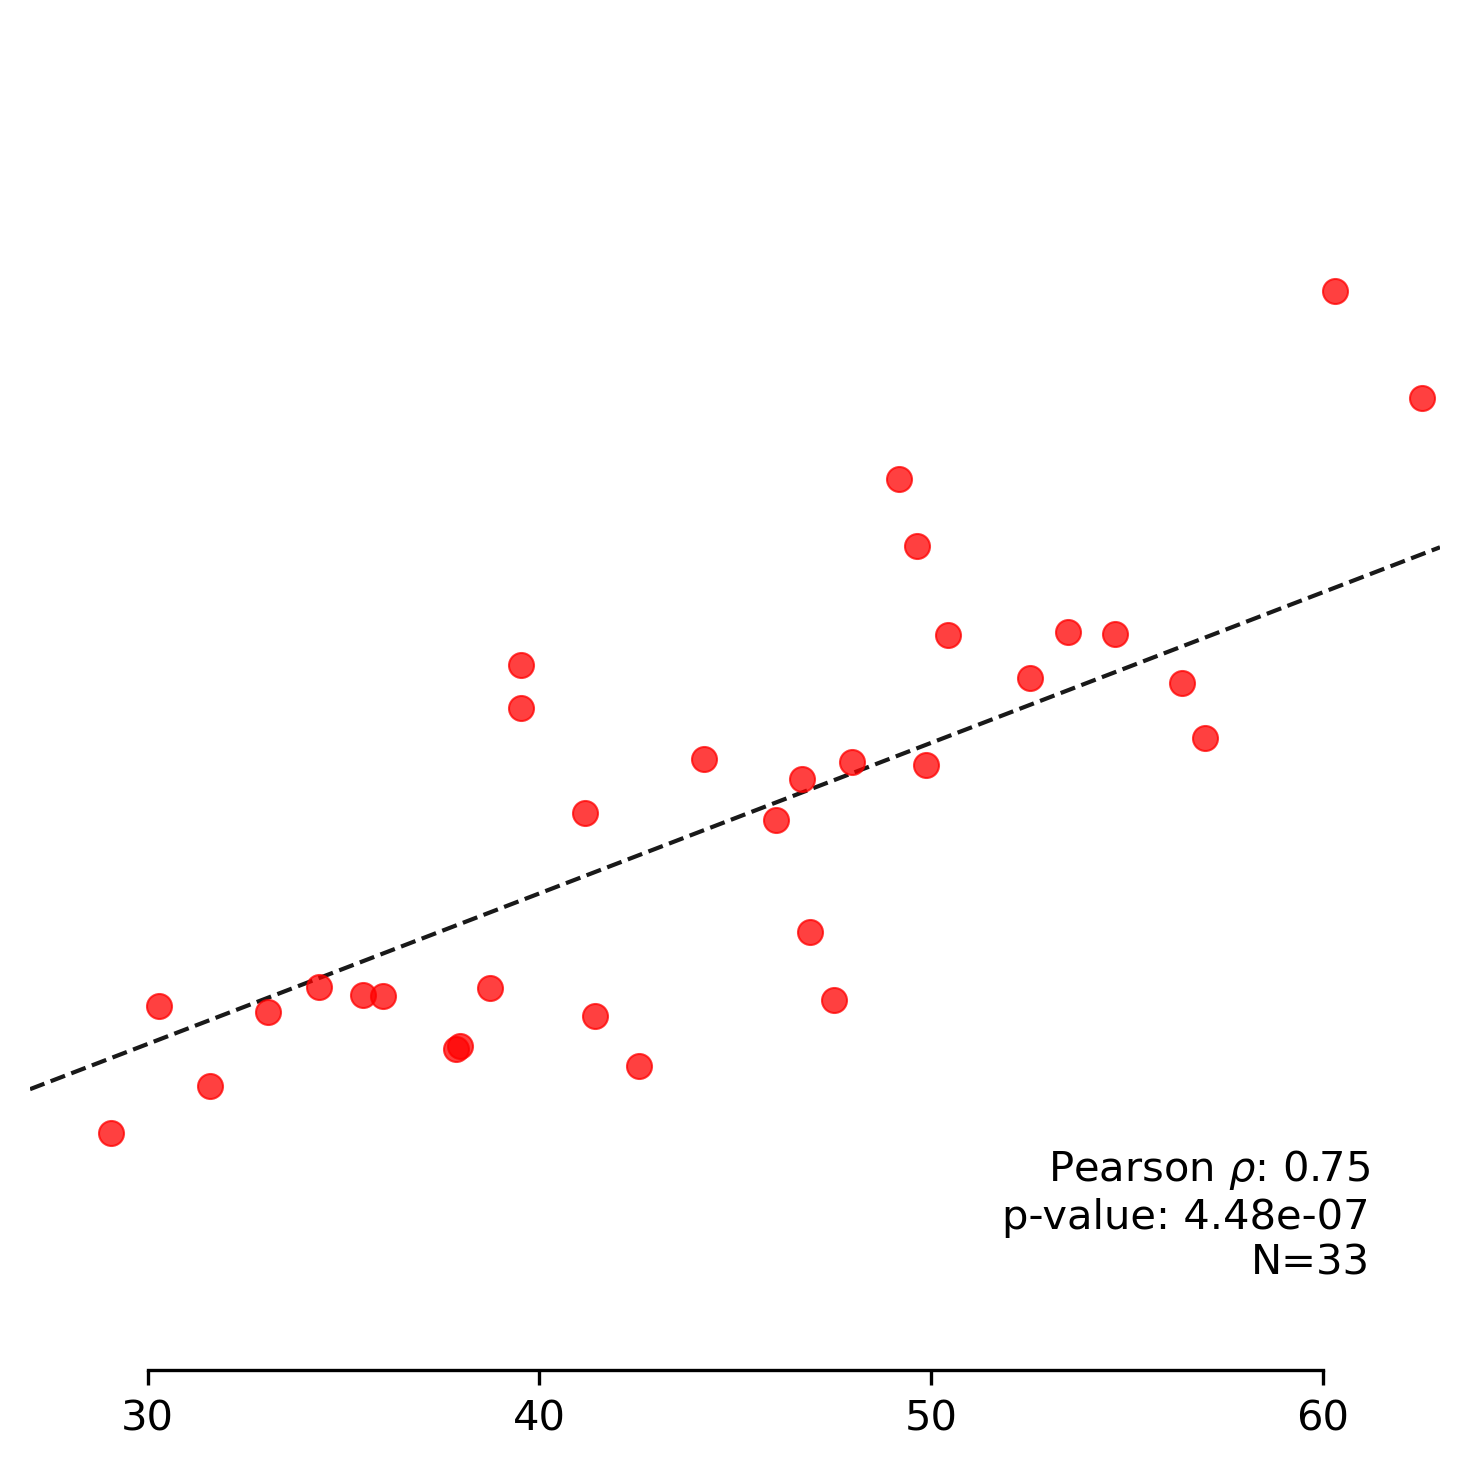

FFA


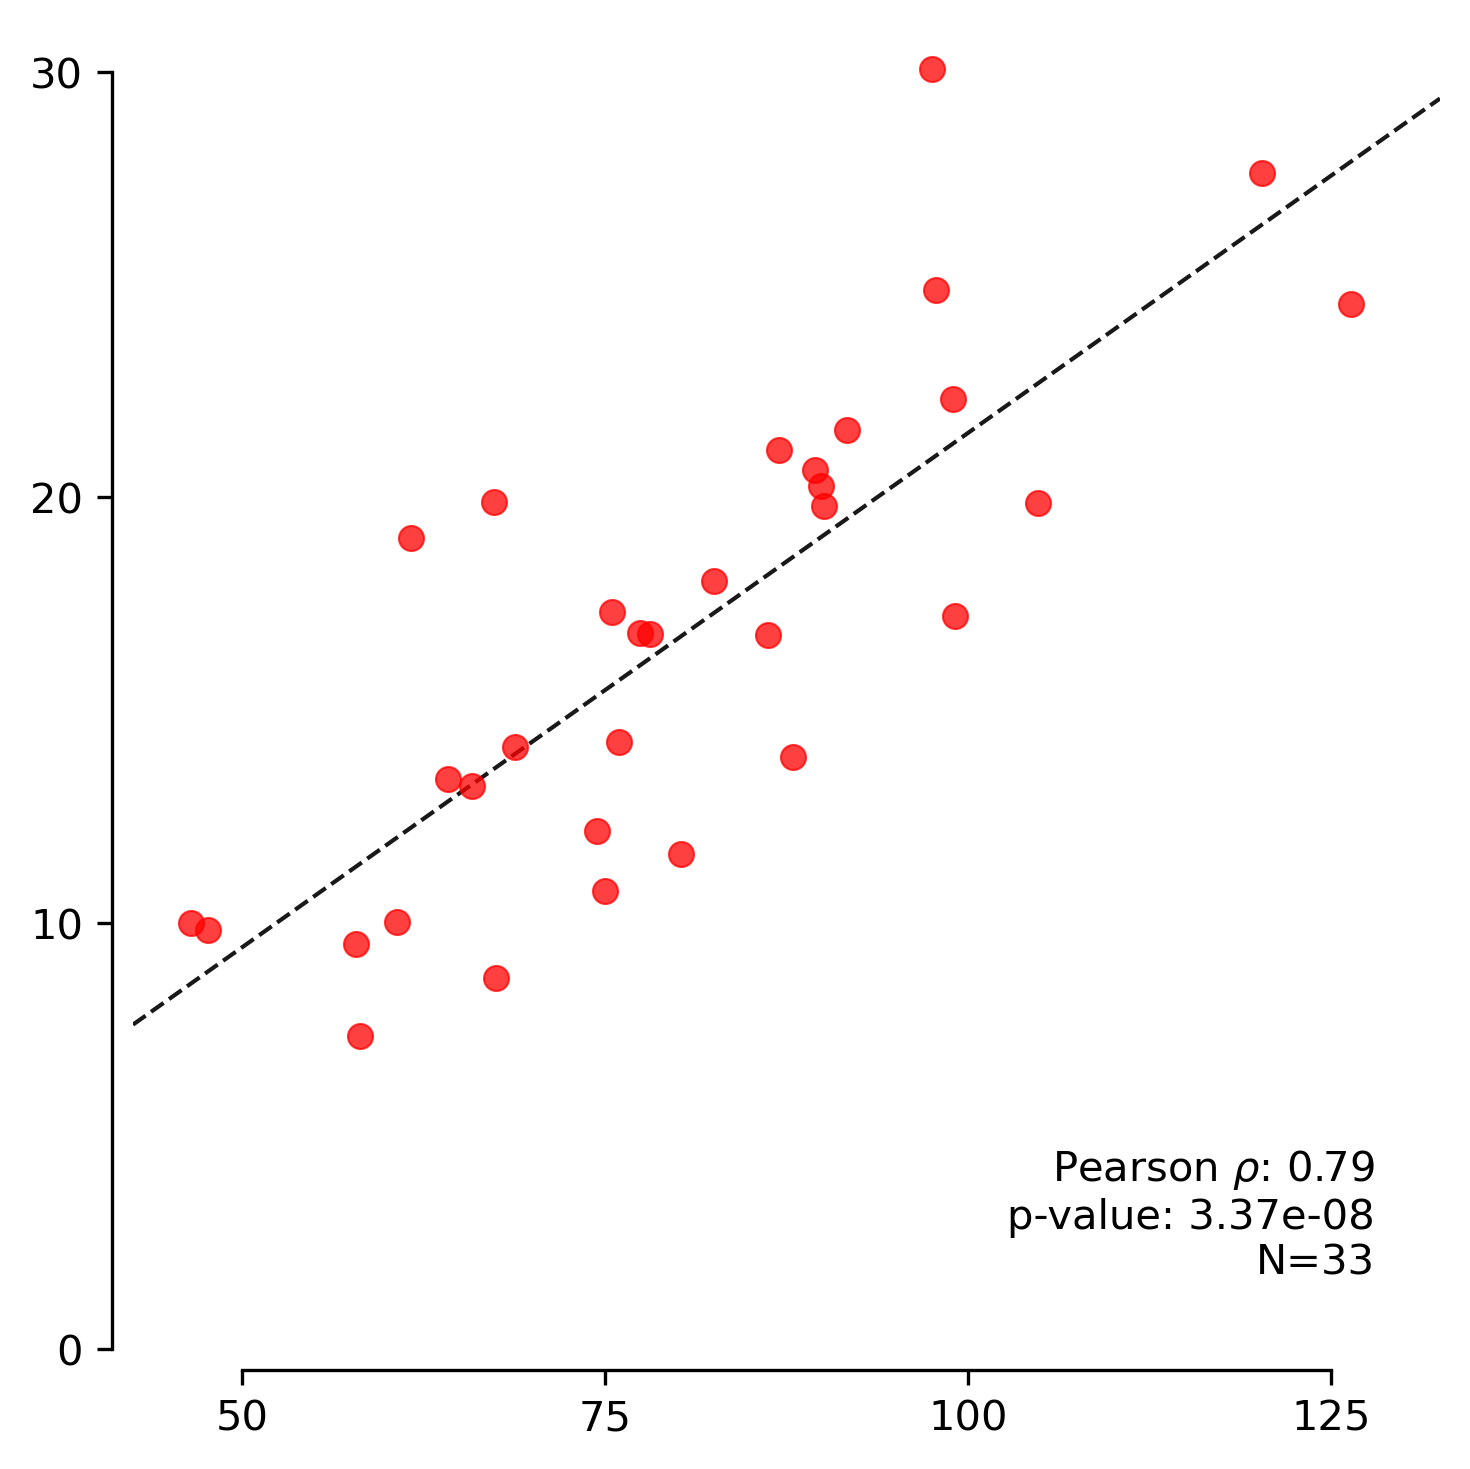

EBA


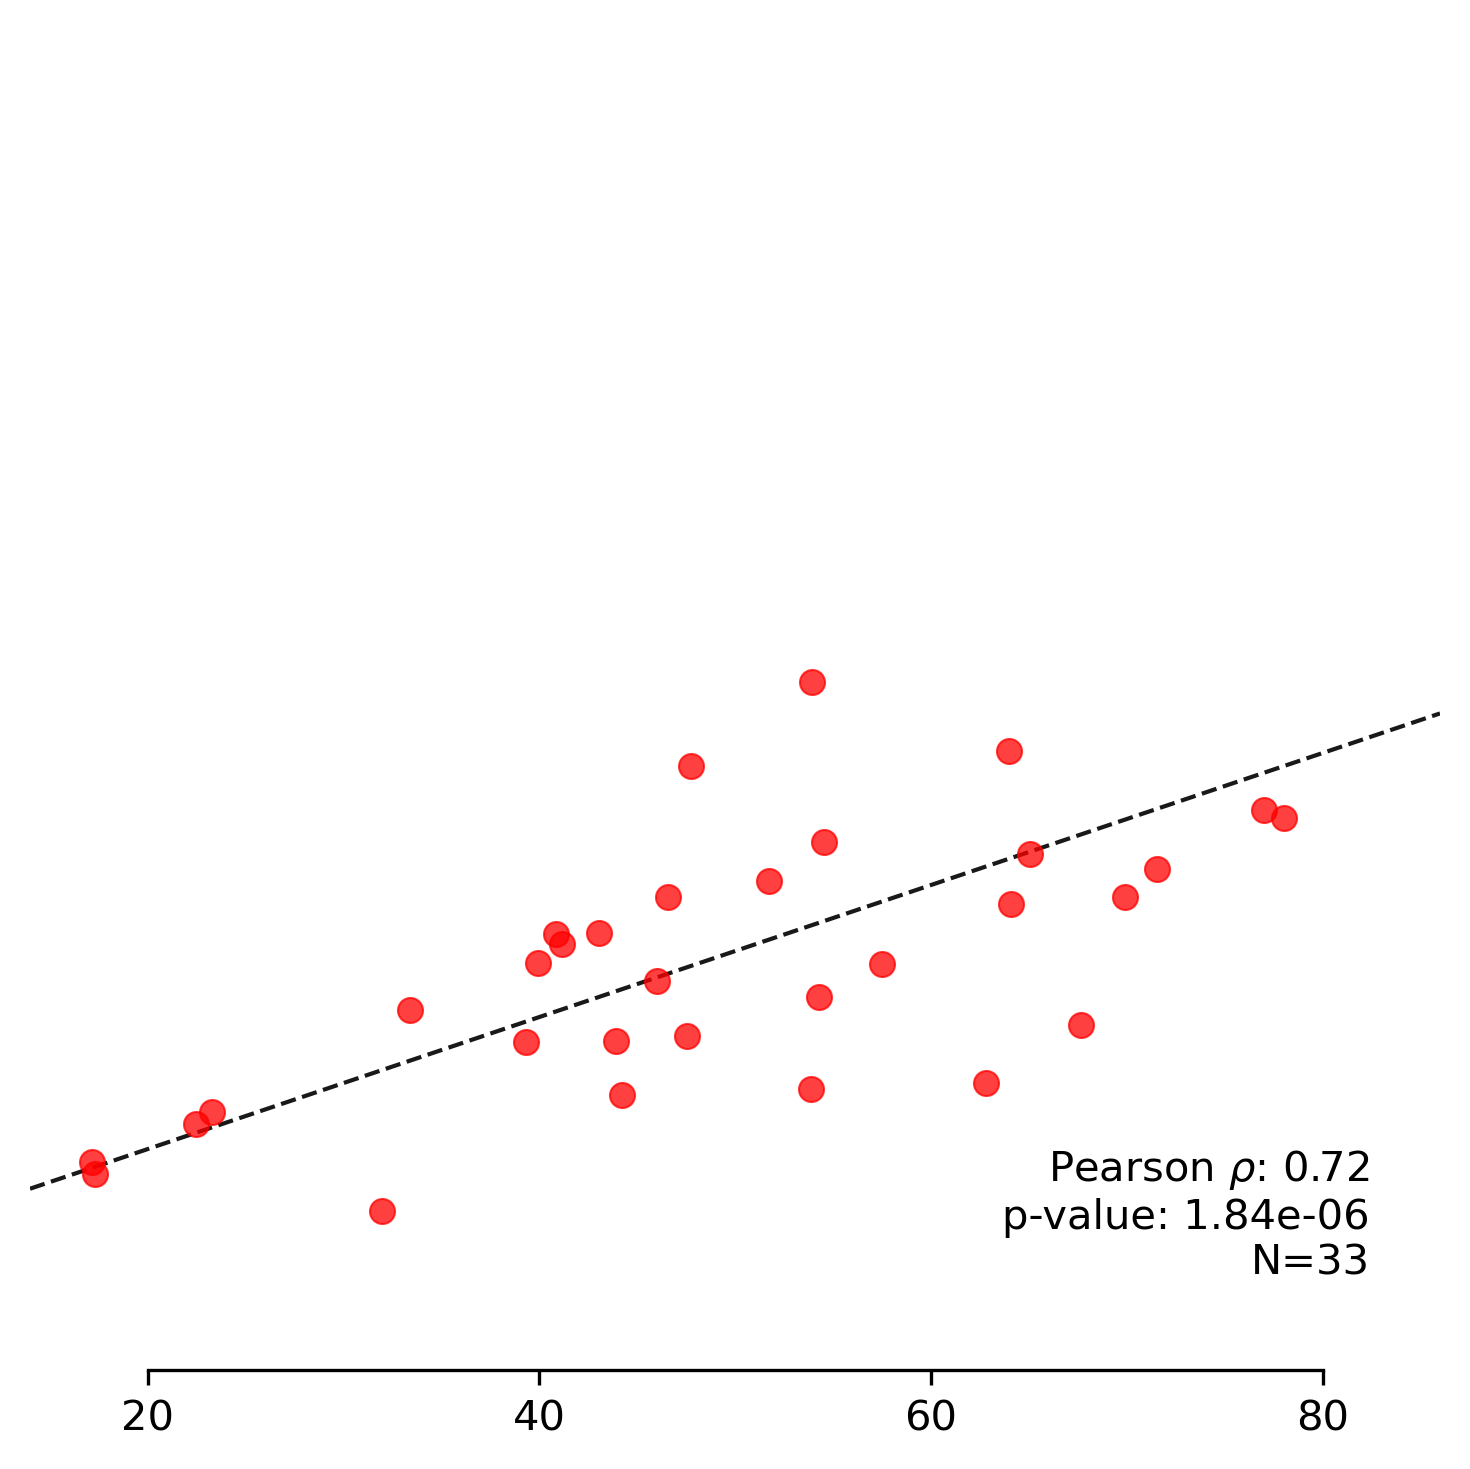

In [ ]:
# Grill-Spector localization validation on X localizer
savefig = False

plot_dir = f'{PLOTS_DIR}/localization_validation'
os.makedirs(plot_dir, exist_ok=True)

localization_validation_df = pd.read_csv(LOCALIZATION_VALIDATION_GS_KO_CSV_DIR)

frois = localization_validation_df['model_froi'].unique()

for froi in frois:
    print(froi)
    froi_df = localization_validation_df[localization_validation_df['model_froi'] == froi]
    localization_tvalues = froi_df['localization_tvalue'].values
    validation_tvalues = froi_df['validation_tvalue'].values
    n_models = len(validation_tvalues)
    # xticks_lowlim = int(np.floor(min(localization_tvalues) / 20) * 20)
    # xticks_highlim = int(max(localization_tvalues) + 20)
    # x_range = np.linspace(xticks_lowlim, xticks_highlim, 100)

    fig = plt.figure(figsize=(5, 5), dpi=300)
    xpadpercent = 0.1
    if froi == 'FFA':
        plt.xticks([50, 75, 100, 125])
        xpad = (125 - 50) * xpadpercent
        plt.xlim(50 - xpad, 125 + xpad)
        plt.gca().spines['bottom'].set_bounds(50, 125)
    elif froi == 'PPA':
        # plt.xticks([20, 40, 60, 80])
        # plt.xlim(15, 85)
        # plt.gca().spines['bottom'].set_bounds(20, 80)
        plt.xticks([30, 40, 50, 60])
        xpad = (60 - 30) * xpadpercent
        plt.xlim(30 - xpad, 60 + xpad)
        plt.gca().spines['bottom'].set_bounds(30, 60)
    elif froi == 'EBA':
        plt.xticks([20, 40, 60, 80])
        xpad = (80 - 20) * xpadpercent
        plt.xlim(20 - xpad, 80 + xpad)
        plt.gca().spines['bottom'].set_bounds(20, 80)
    xmin, xmax = plt.xlim()
    x_range = np.linspace(xmin, xmax, 100)
    m, b = np.polyfit(localization_tvalues, validation_tvalues, 1)
    plt.plot(x_range, m*x_range + b, 'k--', alpha=0.9, linewidth=1, clip_on=True)
    # plt.plot(localization_tvalues, m*localization_tvalues + b, 'k--', alpha=0.9)
    plt.scatter(localization_tvalues, validation_tvalues, color='red', alpha=0.75, zorder=2, linewidths=0.5)

    # Calculate Pearson correlation
    r, p_value = scipy.stats.pearsonr(localization_tvalues, validation_tvalues)
    plt.text(0.95, 0.05,
             rf"Pearson $\rho$: {r:.2f}" + '\n' + f"p-value: {p_value:.2e}" +  '\n'+  f"N={n_models}",
             horizontalalignment='right', verticalalignment='bottom',
             transform=plt.gca().transAxes)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 10, 20, 30])
    plt.gca().spines['left'].set_bounds(0, 30)
    plt.ylim(0, 31)

    if froi != 'FFA':
        plt.gca().spines['left'].set_visible(False)
        # Stop showing y-axis ticks
        plt.gca().yaxis.set_ticks([])
    
    # plt.yticks(np.arange(5, int(max(validation_tvalues)+5), 5))
    # plt.xticks(
    #     np.arange(
    #         xticks_lowlim,
    #         xticks_highlim, 20
    #     )
    # )
    # plt.xlim(xticks_lowlim, xticks_highlim)
    # plt.xticks([0, 25, 50, 75, 100, 125])
    # plt.xlim(0, 130)
    # plt.gca().spines['bottom'].set_bounds(0, 125)
    # plt.xlabel('Localization t-values (Grill-Spector, t>7)')
    # plt.ylabel('Validation t-values (Konkle)')
    # plt.title(f'{froi} Localization: t-value of pref. vs. all others')
    plt.tight_layout()
    if savefig:
        plt.savefig(f'{plot_dir}/localization_validation_grillspector-konkle_{froi}.png', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    plt.close()

## Grillspector -> Kanwisher

FFA


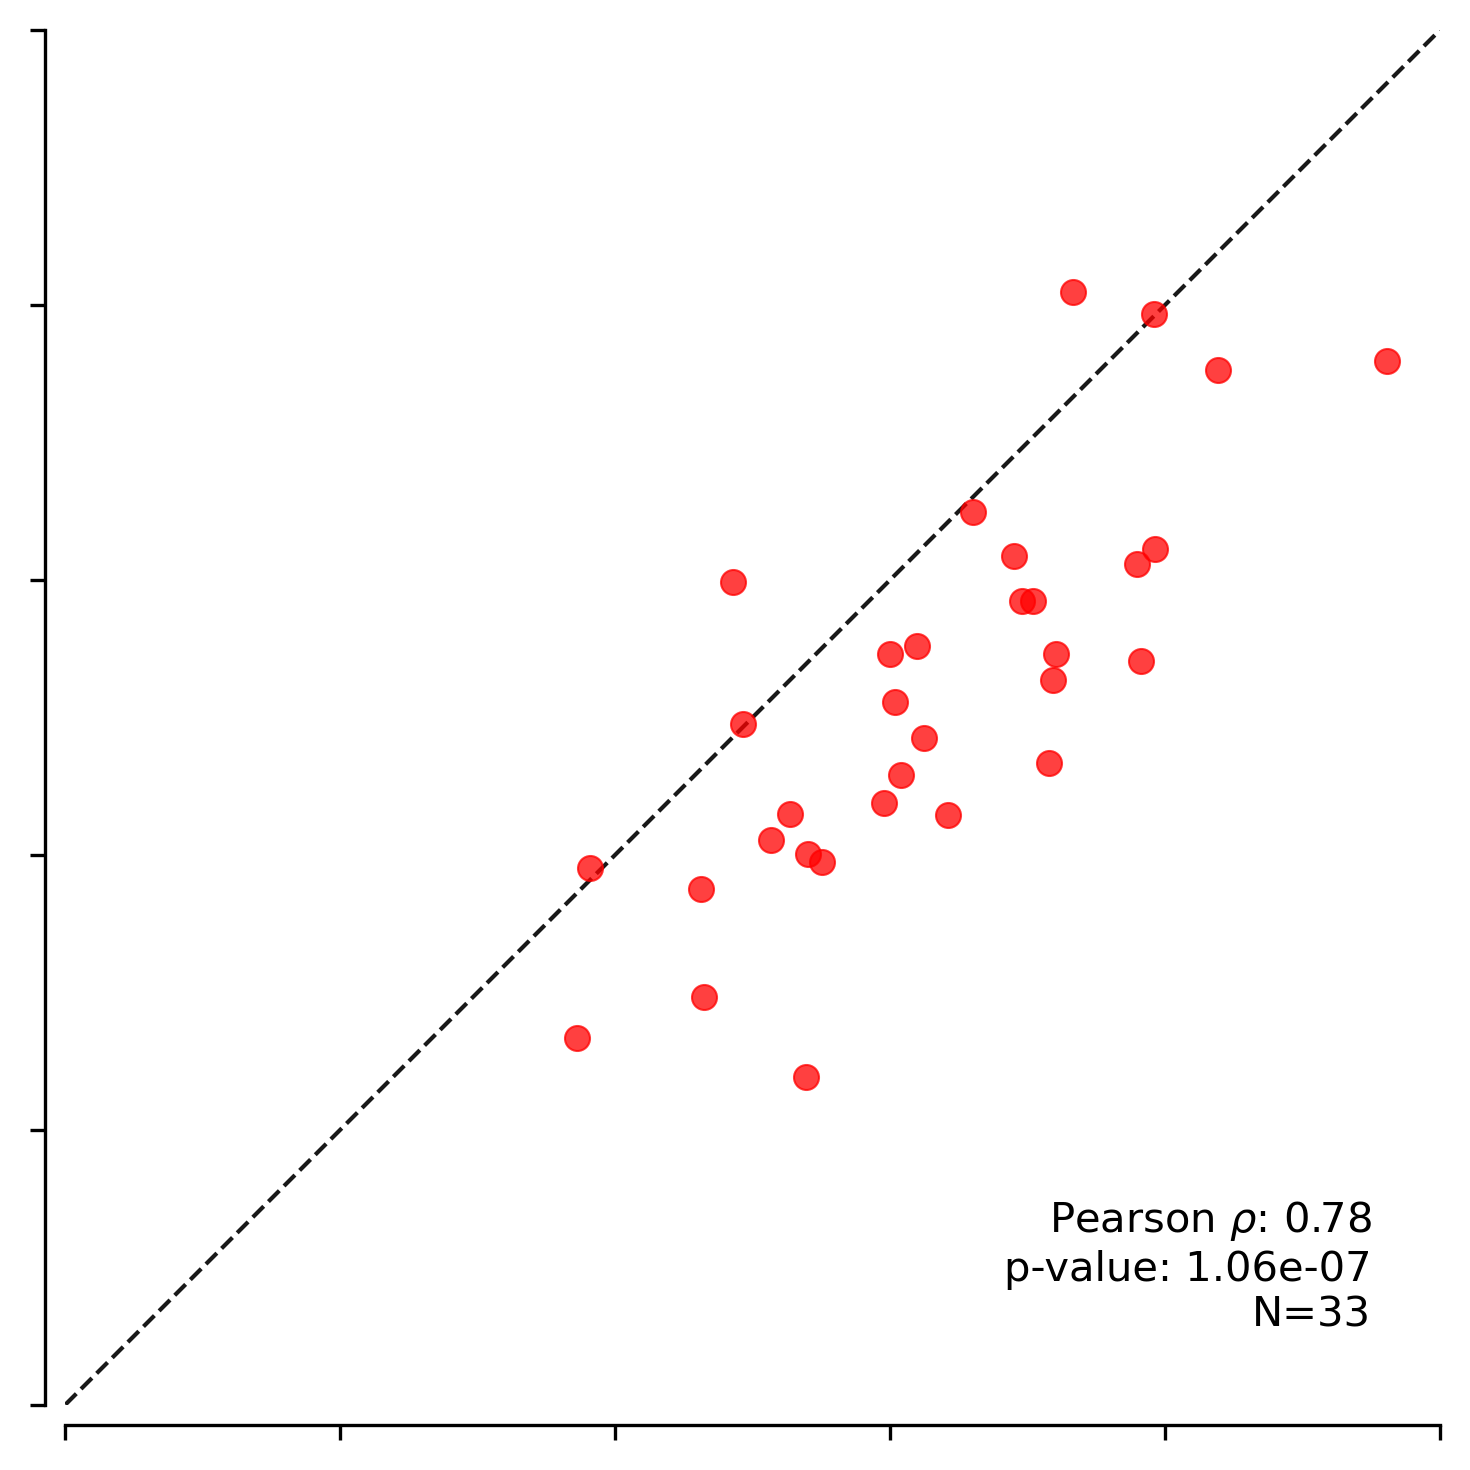

PPA


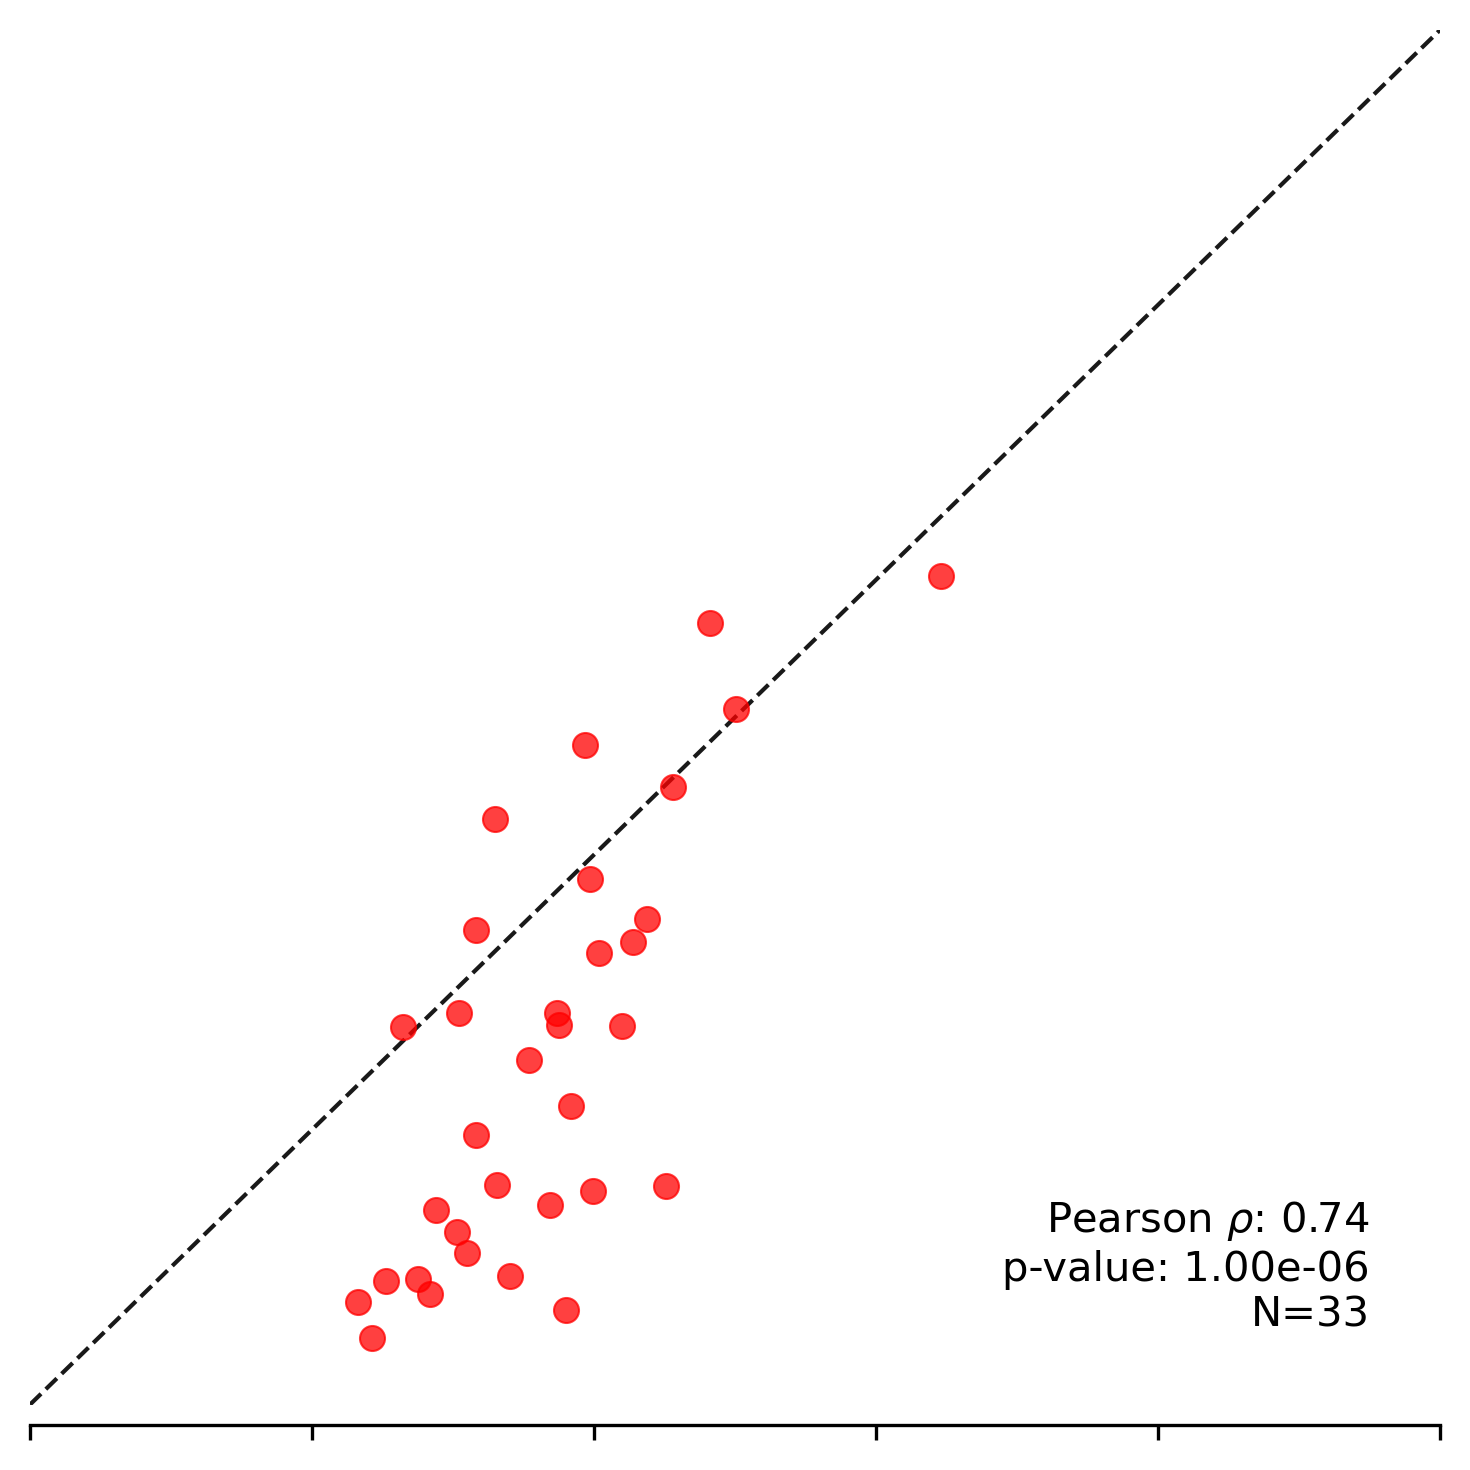

EBA


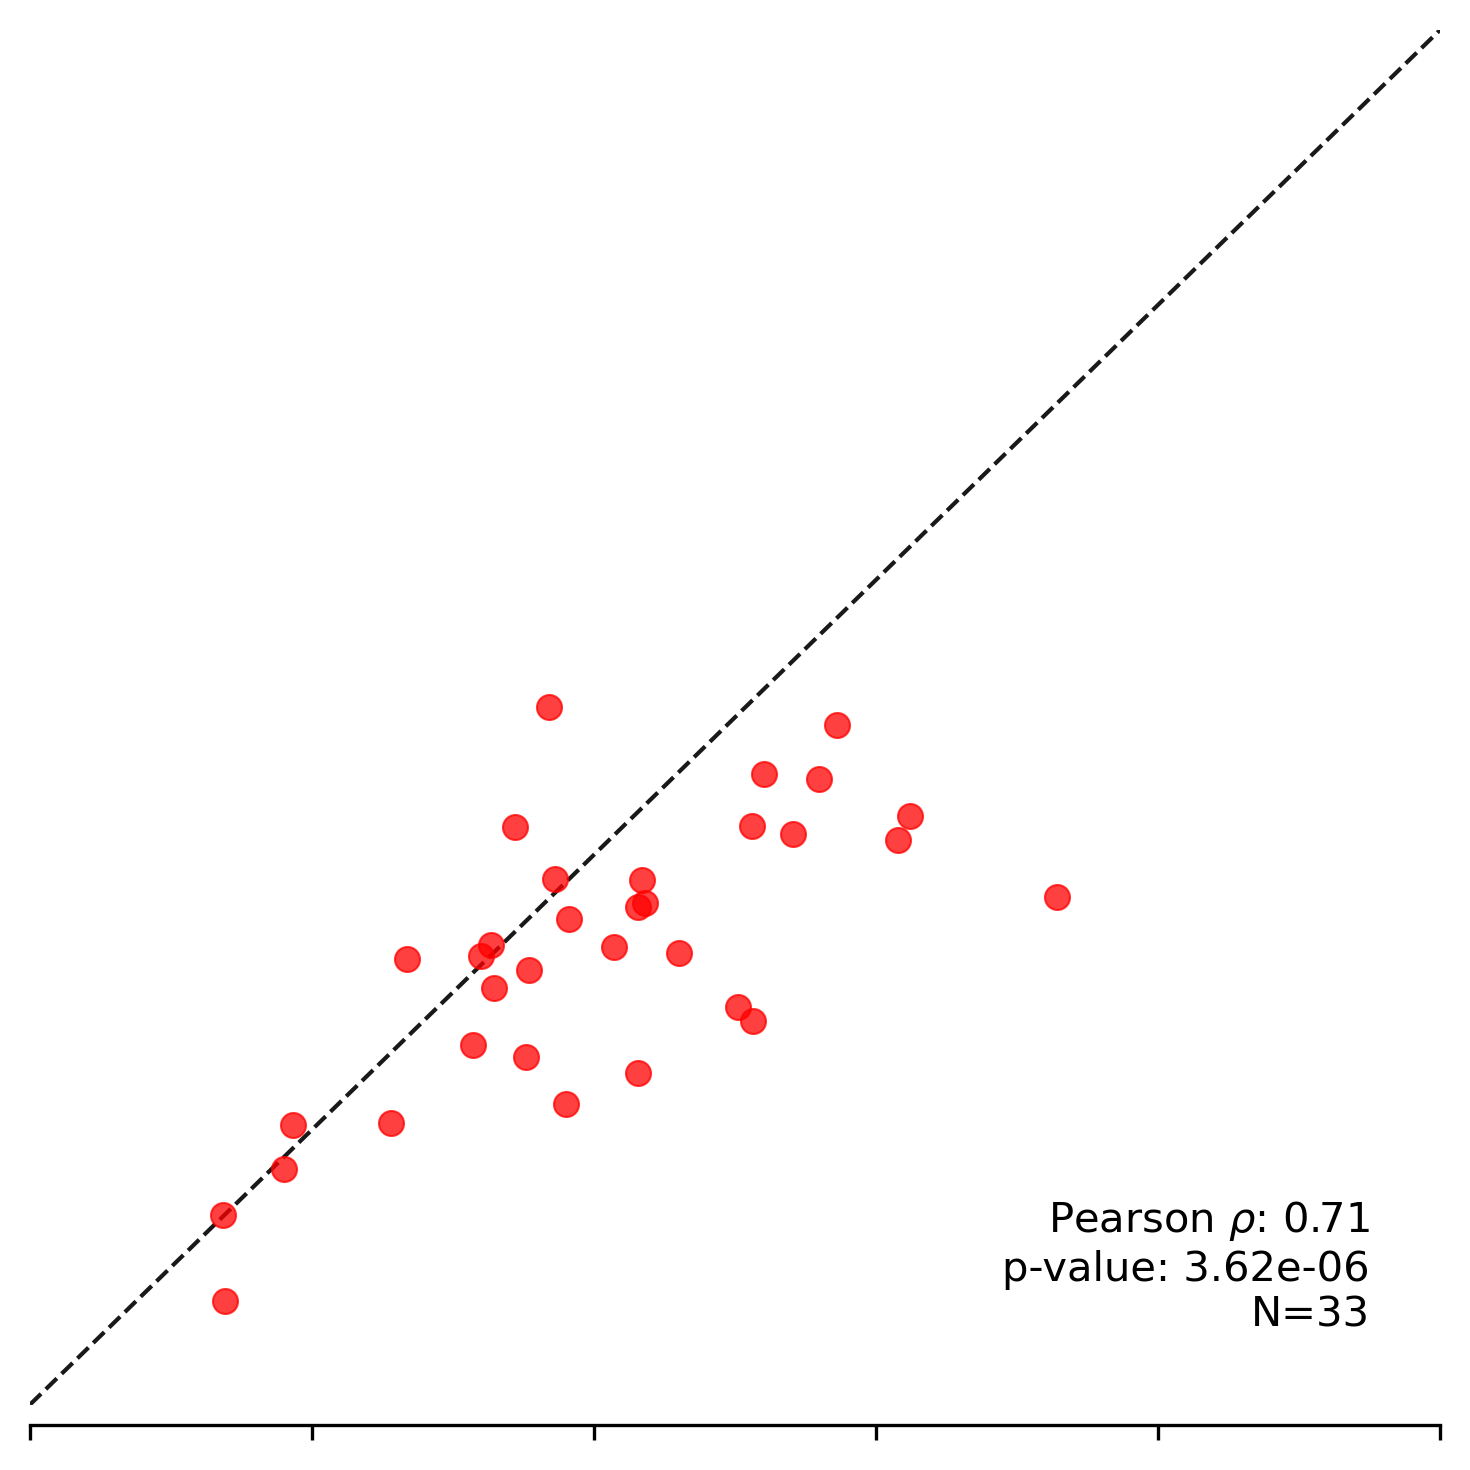

In [92]:
# Grill-Spector localization validation on X localizer
savefig = False

plot_dir = f'{PLOTS_DIR}/localization_validation'
os.makedirs(plot_dir, exist_ok=True)

localization_validation_df = pd.read_csv(LOCALIZATION_VALIDATION_GS_KW_CSV_DIR)

frois = localization_validation_df['model_froi'].unique()

for froi in frois:
    print(froi)
    froi_df = localization_validation_df[localization_validation_df['model_froi'] == froi]
    localization_tvalues = froi_df['localization_tvalue'].values
    validation_tvalues = froi_df['validation_tvalue'].values
    n_models = len(validation_tvalues)
    # xticks_lowlim = int(np.floor(min(localization_tvalues) / 20) * 20)
    # xticks_highlim = int(max(localization_tvalues) + 20)
    # x_range = np.linspace(xticks_lowlim, xticks_highlim, 100)

    fig = plt.figure(figsize=(5, 5), dpi=300)
    xpadpercent = 0.1
    plt.xticks([0, 25, 50, 75, 100, 125])
    plt.xlim(0, 125)
    plt.gca().spines['bottom'].set_bounds(0, 125)
    xmin, xmax = plt.xlim()
    x_range = np.linspace(xmin, xmax, 100)
    plt.plot(x_range, x_range, 'k--', alpha=0.9, linewidth=1, clip_on=True)
    # m, b = np.polyfit(localization_tvalues, validation_tvalues, 1)
    # plt.plot(x_range, m*x_range + b, 'k--', alpha=0.9, linewidth=1, clip_on=True)
    # plt.plot(localization_tvalues, m*localization_tvalues + b, 'k--', alpha=0.9)
    plt.scatter(localization_tvalues, validation_tvalues, color='red', alpha=0.75, zorder=2, linewidths=0.5)

    # Calculate Pearson correlation
    r, p_value = scipy.stats.pearsonr(localization_tvalues, validation_tvalues)
    plt.text(0.95, 0.05,
             rf"Pearson $\rho$: {r:.2f}" + '\n' + f"p-value: {p_value:.2e}" +  '\n'+  f"N={n_models}",
             horizontalalignment='right', verticalalignment='bottom',
             transform=plt.gca().transAxes)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 25, 50, 75, 100, 125])
    plt.ylim(0, 125)
    plt.gca().spines['left'].set_bounds(0, 125)

    # Turn off tick labels
    plt.gca().tick_params(axis='x', which='both', labelleft=False, labelbottom=False)
    plt.gca().tick_params(axis='y', which='both', labelleft=False)

    if froi != 'FFA':
        plt.gca().spines['left'].set_visible(False)
        plt.gca().yaxis.set_ticks([])
    
    # plt.yticks(np.arange(5, int(max(validation_tvalues)+5), 5))
    # plt.xticks(
    #     np.arange(
    #         xticks_lowlim,
    #         xticks_highlim, 20
    #     )
    # )
    # plt.xlim(xticks_lowlim, xticks_highlim)
    # plt.xticks([0, 25, 50, 75, 100, 125])
    # plt.xlim(0, 130)
    # plt.gca().spines['bottom'].set_bounds(0, 125)
    # plt.xlabel('Localization t-values (Grill-Spector, t>7)')
    # plt.ylabel('Validation t-values (Konkle)')
    # plt.title(f'{froi} Localization: t-value of pref. vs. all others')
    plt.tight_layout()
    if savefig:
        plt.savefig(f'{plot_dir}/localization_validation_grillspector-kanwisher_{froi}.png', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    plt.close()

# Comparing response magnitudes

In [ ]:
# Old

savefig = False

plot_dir = f'{PLOTS_DIR}/v1/modelhuman_univariate'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'
annotate_models = False

metric = 'normed_pearsonr' # 'pearsonr'

for froi in frois:
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject) &
            (subjectsubject_correlations_csv['fmri_tthreshold'] == 7)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == 7) &
            (modelsubject_correlations_csv['model_tthreshold'] == 7)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    best_model_idx = np.argmax(mh_medians)
    worst_model_idx = np.argmin(mh_medians)
    median_model_idx = np.argsort(mh_medians)[len(mh_medians) // 2]
    best_model_name = models[best_model_idx]
    worst_model_name = models[worst_model_idx]
    median_model_name = models[median_model_idx]

    resnet50imagenet1kv2_idx = np.where(models == 'resnet50imagenet1kv2')[0][0]
    resnet50imagenet1kv2_name = models[resnet50imagenet1kv2_idx]

    fig = plt.figure(figsize=(5, 5), dpi=300)
    jitter_scale = 0.01 #0.05
    scatter_pad = -0.075
    alpha = 0.5
    markersize = 25

    x = np.array([0, 0.45])

    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*x[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    # plt.errorbar(
    #     x_modelsubject, mh_medians, yerr=mh_sems, fmt='o', ecolor='k', \
    #     capsize=0, label='Model-Subject', markerfacecolor=mh_color, markeredgecolor=mh_color, \
    #     zorder=1, alpha=0.5
    # )
    plt.scatter(
        x_subjectsubject, hh_medians, color='blue', alpha=alpha, label='Subject-Subject', zorder=2,
        edgecolors='none', s=markersize
    )
    plt.scatter(
        x_modelsubject, mh_medians, color='red', alpha=alpha, label='Model-Subject', zorder=2,
        edgecolors='none', s=markersize
    )
    # Bar plot with median and SEM
    bar_width = 0.3 #0.4
    medians = [np.median(hh_medians), np.median(mh_medians)]
    sems = [hh_medians.std() / np.sqrt(len(hh_medians)), mh_medians.std() / np.sqrt(len(mh_medians))]

    plt.bar(x, medians, yerr=sems, width=bar_width, color=['blue', 'red'], alpha=0.25, capsize=2, error_kw={'linewidth': 1})
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    plt.text(0.95, 0.89,
             f"t-value: {t_value:.2f}\np-value: {p_value:.2e}",
             horizontalalignment='right', verticalalignment='bottom',
             transform=plt.gca().transAxes)
    plt.xticks(
        x, [f'Subject-Subject\nN={len(subjects)+1}*({len(subjects)+1}-1)', 
                    f'Model-Subject\nN={len(models)}']
    )
    # plt.gca().spines['top'].set_visible(False)
    # plt.gca().spines['right'].set_visible(False)
    # plt.ylabel(r'Normalized pearson $\rho$')
    # plt.title(f'Univariate Comparison: {froi}')
    # plt.yticks(np.arange(0, 1.01, 0.2))
    # plt.xlim(-0.5, 1.5)
    # plt.ylim(0, 1.25)

    plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 0.25, 0.5, 0.75, 1])
    plt.gca().spines['left'].set_bounds(0, 1)
    plt.ylim(0, 1.25)
    plt.gca().spines['bottom'].set_bounds(x[0], x[1])
    plt.xlim(x[0]-0.25, x[1]+0.25)
    plt.tick_params(axis='x', labelbottom=False)

    if froi != 'FFA':
        plt.gca().spines['left'].set_visible(False)
        # Stop showing y-axis ticks
        plt.gca().yaxis.set_ticks([])

    if savefig:
        plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.png', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    # plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
    plt.close()

In [91]:
savefig = True

plot_dir = f'{PLOTS_DIR}/v2/modelhuman_univariate'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'
annotate_models = False

metric = 'normed_pearsonr' # 'pearsonr'

for froi in frois:
    print(froi)
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject) &
            (subjectsubject_correlations_csv['fmri_tthreshold'] == 7)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == 7) &
            (modelsubject_correlations_csv['model_tthreshold'] == 7)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    best_model_idx = np.argmax(mh_medians)
    worst_model_idx = np.argmin(mh_medians)
    median_model_idx = np.argsort(mh_medians)[len(mh_medians) // 2]
    best_model_name = models[best_model_idx]
    worst_model_name = models[worst_model_idx]
    median_model_name = models[median_model_idx]

    resnet50imagenet1kv2_idx = np.where(models == 'resnet50imagenet1kv2')[0][0]
    resnet50imagenet1kv2_name = models[resnet50imagenet1kv2_idx]

    fig = plt.figure(figsize=(5, 5), dpi=300)
    jitter_scale = 0.01 #0.05
    scatter_pad = -0.05
    alpha = 0.5
    markersize = 25

    x = np.array([0, 0.3])

    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*x[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    # plt.errorbar(
    #     x_modelsubject, mh_medians, yerr=mh_sems, fmt='o', ecolor='k', \
    #     capsize=0, label='Model-Subject', markerfacecolor=mh_color, markeredgecolor=mh_color, \
    #     zorder=1, alpha=0.5
    # )
    plt.scatter(
        x_subjectsubject, hh_medians, color='blue', alpha=alpha, label='Subject-Subject', zorder=2,
        edgecolors='none', s=markersize
    )
    plt.scatter(
        x_modelsubject, mh_medians, color='red', alpha=alpha, label='Model-Subject', zorder=2,
        edgecolors='none', s=markersize
    )
    # Bar plot with median and SEM
    bar_width = 0.2 #0.4
    medians = [np.median(hh_medians), np.median(mh_medians)]
    sems = [hh_medians.std() / np.sqrt(len(hh_medians)), mh_medians.std() / np.sqrt(len(mh_medians))]

    plt.bar(x, medians, yerr=sems, width=bar_width, color=['blue', 'red'], alpha=0.25, capsize=0, error_kw={'linewidth': 1})
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    # plt.text(0.95, 0.89,
    #          f"t-value: {t_value:.2f}\np-value: {p_value:.2e}",
    #          horizontalalignment='right', verticalalignment='bottom',
    #          transform=plt.gca().transAxes)
    # plt.xticks(
    #     x, [f'Subject-Subject\nN={len(subjects)+1}*({len(subjects)+1}-1)', 
    #                 f'Model-Subject\nN={len(models)}']
    # )
    plt.xticks(x)
    print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')
    # plt.gca().spines['top'].set_visible(False)
    # plt.gca().spines['right'].set_visible(False)
    # plt.ylabel(r'Normalized pearson $\rho$')
    # plt.title(f'Univariate Comparison: {froi}')
    # plt.yticks(np.arange(0, 1.01, 0.2))
    # plt.xlim(-0.5, 1.5)
    # plt.ylim(0, 1.25)

    plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 0.25, 0.5, 0.75, 1])
    plt.gca().spines['left'].set_bounds(0, 1)
    plt.tick_params(axis='y', labelleft=False)
    plt.ylim(0, 1.15)
    plt.gca().spines['bottom'].set_bounds(x[0], x[1])
    plt.xlim(x[0]-0.25, x[1]+0.25)
    plt.tick_params(axis='x', labelbottom=False)

    if froi != 'FFA':
        plt.gca().spines['left'].set_visible(False)
        # Stop showing y-axis ticks
        plt.gca().yaxis.set_ticks([])

    if savefig:
        plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.png', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    # plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
    plt.close()

FFA
t-value: 21.68, p-value: 1.30e-26
PPA
t-value: 21.38, p-value: 9.43e-29
EBA
t-value: 19.22, p-value: 2.56e-25


# Comparing representational geometry

In [ ]:
# Old

savefig = False

plot_dir = f'{PLOTS_DIR}/modelhuman_multivariate'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'royalblue'
mh_color = 'red'
annotate_models = False

metric = 'normed_rdmr' # 'pearsonr'

for froi in frois:
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    best_model_idx = np.argmax(mh_medians)
    worst_model_idx = np.argmin(mh_medians)
    median_model_idx = np.argsort(mh_medians)[len(mh_medians) // 2]
    best_model_name = models[best_model_idx]
    worst_model_name = models[worst_model_idx]
    median_model_name = models[median_model_idx]

    resnet50imagenet1kv2_idx = np.where(models == 'resnet50imagenet1kv2')[0][0]
    resnet50imagenet1kv2_name = models[resnet50imagenet1kv2_idx]

    fig = plt.figure(figsize=(5, 5), dpi=300)
    jitter_scale = 0.01 #0.05
    scatter_pad = -0.075
    alpha = 0.5
    markersize = 25

    x = np.array([0, 0.45])

    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*x[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    # plt.errorbar(
    #     x_modelsubject, mh_medians, yerr=mh_sems, fmt='o', ecolor='k', \
    #     capsize=0, label='Model-Subject', markerfacecolor=mh_color, markeredgecolor=mh_color, \
    #     zorder=1, alpha=0.5
    # )
    plt.scatter(
        x_subjectsubject, hh_medians, color='blue', alpha=alpha, label='Subject-Subject', zorder=2,
        edgecolors='none', s=markersize
    )
    plt.scatter(
        x_modelsubject, mh_medians, color='red', alpha=alpha, label='Model-Subject', zorder=2,
        edgecolors='none', s=markersize
    )
    # Bar plot with median and SEM
    bar_width = 0.3 #0.4
    medians = [np.median(hh_medians), np.median(mh_medians)]
    sems = [hh_medians.std() / np.sqrt(len(hh_medians)), mh_medians.std() / np.sqrt(len(mh_medians))]

    plt.bar(x, medians, yerr=sems, width=bar_width, color=['blue', 'red'], alpha=0.25, capsize=2, error_kw={'linewidth': 1})
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    plt.text(0.95, 0.89,
             f"t-value: {t_value:.2f}\np-value: {p_value:.2e}",
             horizontalalignment='right', verticalalignment='bottom',
             transform=plt.gca().transAxes)
    plt.xticks(
        x, [f'Subject-Subject\nN={len(subjects)+1}*({len(subjects)+1}-1)', 
                    f'Model-Subject\nN={len(models)}']
    )
    # plt.gca().spines['top'].set_visible(False)
    # plt.gca().spines['right'].set_visible(False)
    # plt.ylabel(r'Normalized pearson $\rho$')
    # plt.title(f'Univariate Comparison: {froi}')
    # plt.yticks(np.arange(0, 1.01, 0.2))
    # plt.xlim(-0.5, 1.5)
    # plt.ylim(0, 1.25)

    plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 0.25, 0.5, 0.75, 1])
    plt.gca().spines['left'].set_bounds(0, 1)
    plt.ylim(0, 1.5)
    plt.gca().spines['bottom'].set_bounds(x[0], x[1])
    plt.xlim(x[0]-0.25, x[1]+0.25)
    plt.tick_params(axis='x', labelbottom=False)

    if froi != 'FFA':
        plt.gca().spines['left'].set_visible(False)
        # Stop showing y-axis ticks
        plt.gca().yaxis.set_ticks([])

    if savefig:
        plt.savefig(f'{plot_dir}/modelhuman_multuivariate_{froi}.png', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    # plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
    plt.close()

In [101]:
savefig = True

plot_dir = f'{PLOTS_DIR}/v2/modelhuman_multivariate'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
frois = ['FFA', 'PPA', 'EBA']
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

hh_color = 'blue'
mh_color = 'red'
annotate_models = False

metric = 'normed_rdmr' # 'pearsonr'

for froi in frois:
    print(froi)
    hh_medians = []
    for subject in subjects:
        subjectsubject_froi = subjectsubject_correlations_csv[
            (subjectsubject_correlations_csv['fmri_froi'] == froi) &
            (subjectsubject_correlations_csv['subject1'] == subject) &
            (subjectsubject_correlations_csv['fmri_tthreshold'] == 7)
        ]
        hh_medians += list(subjectsubject_froi[metric])
    hh_medians = np.array(hh_medians).flatten()

    mh_medians, mh_sems = [], []
    for model in models:
        modelsubject_froi = modelsubject_correlations_csv[
            (modelsubject_correlations_csv['fmri_froi'] == froi) &
            (modelsubject_correlations_csv['model_name'] == model) &
            (modelsubject_correlations_csv['fmri_tthreshold'] == 7) &
            (modelsubject_correlations_csv['model_tthreshold'] == 7)
        ]
        mh_medians.append(modelsubject_froi[metric].median())
        mh_sems.append(modelsubject_froi[metric].sem())
    mh_medians = np.array(mh_medians)
    mh_sems = np.array(mh_sems)

    best_model_idx = np.argmax(mh_medians)
    worst_model_idx = np.argmin(mh_medians)
    median_model_idx = np.argsort(mh_medians)[len(mh_medians) // 2]
    best_model_name = models[best_model_idx]
    worst_model_name = models[worst_model_idx]
    median_model_name = models[median_model_idx]

    resnet50imagenet1kv2_idx = np.where(models == 'resnet50imagenet1kv2')[0][0]
    resnet50imagenet1kv2_name = models[resnet50imagenet1kv2_idx]

    fig = plt.figure(figsize=(5, 5), dpi=300)
    jitter_scale = 0.01 #0.05
    scatter_pad = -0.05
    alpha = 0.5
    markersize = 25

    x = np.array([0, 0.3])

    x_subjectsubject = np.zeros(len(hh_medians)) + np.random.normal(0, jitter_scale, len(hh_medians)) 
    x_modelsubject = np.ones(len(mh_medians))*x[1] + np.random.normal(0, jitter_scale, len(mh_medians))
    x_subjectsubject += scatter_pad
    x_modelsubject += scatter_pad
    # plt.errorbar(
    #     x_modelsubject, mh_medians, yerr=mh_sems, fmt='o', ecolor='k', \
    #     capsize=0, label='Model-Subject', markerfacecolor=mh_color, markeredgecolor=mh_color, \
    #     zorder=1, alpha=0.5
    # )
    plt.scatter(
        x_subjectsubject, hh_medians, color='blue', alpha=alpha, label='Subject-Subject', zorder=2,
        edgecolors='none', s=markersize
    )
    plt.scatter(
        x_modelsubject, mh_medians, color='red', alpha=alpha, label='Model-Subject', zorder=2,
        edgecolors='none', s=markersize
    )
    # Bar plot with median and SEM
    bar_width = 0.2 #0.4
    medians = [np.median(hh_medians), np.median(mh_medians)]
    sems = [hh_medians.std() / np.sqrt(len(hh_medians)), mh_medians.std() / np.sqrt(len(mh_medians))]

    plt.bar(x, medians, yerr=sems, width=bar_width, color=['blue', 'red'], alpha=0.25, capsize=0, error_kw={'linewidth': 1})
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(hh_medians, mh_medians, equal_var=False)
    # plt.text(0.95, 0.89,
    #          f"t-value: {t_value:.2f}\np-value: {p_value:.2e}",
    #          horizontalalignment='right', verticalalignment='bottom',
    #          transform=plt.gca().transAxes)
    # plt.xticks(
    #     x, [f'Subject-Subject\nN={len(subjects)+1}*({len(subjects)+1}-1)', 
    #                 f'Model-Subject\nN={len(models)}']
    # )
    plt.xticks(x)
    print(f't-value: {t_value:.2f}, p-value: {p_value:.2e}')
    # plt.gca().spines['top'].set_visible(False)
    # plt.gca().spines['right'].set_visible(False)
    # plt.ylabel(r'Normalized pearson $\rho$')
    # plt.title(f'Univariate Comparison: {froi}')
    # plt.yticks(np.arange(0, 1.01, 0.2))
    # plt.xlim(-0.5, 1.5)
    # plt.ylim(0, 1.25)

    plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 0.25, 0.5, 0.75, 1])
    plt.gca().spines['left'].set_bounds(0, 1)
    plt.tick_params(axis='y', labelleft=False)
    plt.ylim(0, 1.32)
    plt.gca().spines['bottom'].set_bounds(x[0], x[1])
    plt.xlim(x[0]-0.25, x[1]+0.25)
    plt.tick_params(axis='x', labelbottom=False)

    if froi != 'FFA':
        plt.gca().spines['left'].set_visible(False)
        # Stop showing y-axis ticks
        plt.gca().yaxis.set_ticks([])

    if savefig:
        plt.savefig(f'{plot_dir}/modelhuman_multivariate_{froi}.png', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    # plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
    plt.close()

FFA
t-value: 22.70, p-value: 7.92e-31
PPA
t-value: 24.33, p-value: 9.03e-29
EBA
t-value: 28.94, p-value: 1.49e-36


# Lesions: Paired Bars

## Ridge: v2 (Layer vs t>7 lesioned)

In [2]:
ridge_lesion_csv_path = f'{RESULTS_DIR}/vss_nsd515_ridge_lesion.csv'
ridge_lesion_csvs = [f'{RESULTS_DIR}/vss_nsd515_lesion_ems_ridge_v{i}.csv' for i in range(1, 7)]

if not os.path.exists(ridge_lesion_csv_path):
    ridge_lesion_csv = pd.concat([pd.read_csv(ridge_lesion_csv) for ridge_lesion_csv in ridge_lesion_csvs])
    ridge_lesion_csv.to_csv(ridge_lesion_csv_path, index=False)
else:
    ridge_lesion_csv = pd.read_csv(ridge_lesion_csv_path)

In [ ]:
savefig = True

plot_dir = f'{PLOTS_DIR}/v2/lesions_fulllayer'
os.makedirs(plot_dir, exist_ok=True)

results_df = ridge_lesion_csv.copy()
frois = results_df['model_froi'].unique()

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)

subjects = [1, 2, 5, 7]

ceiling_metric = 'normed_pearsonr' # 'pearsonr'
# ceiling_metric = 'raw_pearsonr'
plot_ceiling = False

# PPA - BagNet33, CorNet-S
# EBA - ['resnet50cesslbarlowtop', 'resnet101imagenet1kv1', 'resnet101openaiclip', 'bagnet33', 'cornets']

for froi in frois:
    print(froi)

    if plot_ceiling:
        ceiling_values = []
        for subject1_idx in range(len(subjects)):
            for subject2_idx in range(subject1_idx, len(subjects)):
                subject1 = subjects[subject1_idx]
                subject2 = subjects[subject2_idx]
                if subject1 == subject2:
                    continue
                subjectsubject_froi = subjectsubject_correlations_csv[
                    (subjectsubject_correlations_csv['fmri_froi'] == froi) &
                    (subjectsubject_correlations_csv['subject1'] == subject1) &
                    (subjectsubject_correlations_csv['subject2'] == subject2) & 
                    (subjectsubject_correlations_csv['fmri_tthreshold'] == 7)
                ]
                ceiling_metric_ = 'pearsonr' if ceiling_metric == 'raw_pearsonr' else ceiling_metric
                ceiling_values += list(subjectsubject_froi[ceiling_metric_])
                # print(f'Subject {subject1} vs Subject {subject2}: {subjectsubject_froi[ceiling_metric]}')
        ceiling_values = np.array(ceiling_values).flatten()
        print(f'Ceiling values: {ceiling_values}')

    model_names = results_df['model'].unique()
    n_models = len(model_names)
    froi_pts, lesion_pts = [], []
    for i in range(len(model_names)):
        model_results = results_df[
                (results_df['model'] == model_names[i]) &
                (results_df['model_froi'] == froi) &
                (results_df['fmri_froi'] == froi)
            ]
        froi_pts.append(model_results[f'layer_{ceiling_metric}'].mean())
        lesion_pts.append(model_results[f'lesion_{ceiling_metric}'].mean())
        # print(f'model name: {model_names[i]}')
        # print(f'Layer points: {model_results[f"layer_{ceiling_metric}"]}')
        # print(f'Lesion points: {model_results[f"lesion_{ceiling_metric}"]}')
    froi_pts = np.array(froi_pts).flatten()
    lesion_pts = np.array(lesion_pts).flatten()
    print(f'Number of points: {len(froi_pts)}')
    print(f'Layer points: {froi_pts}')
    print(f'Lesion points: {lesion_pts}')

    fig = plt.figure(figsize=(5, 5), dpi=300)

    x_offset = 0.05
    alpha = 0.5
    markersize = 25
    x = [0, 0.3]

    # Plot ceiling values
    if plot_ceiling:
        ceiling_median = np.median(ceiling_values)
        ceiling_sem = np.std(ceiling_values) / np.sqrt(len(ceiling_values))

        # Plot horizontal line at median of ceiling values
        plt.axhline(y=ceiling_median, color='royalblue', linestyle='-', alpha=0.8, linewidth=1, zorder=1)

        # Fill area around the line for SEM
        plt.fill_between(
            [x[0]-0.5, x[1]+0.5],  # Extend across full x range
            ceiling_median - ceiling_sem,
            ceiling_median + ceiling_sem,
            color='royalblue', alpha=0.2, zorder=0, edgecolor='none'
        )
    
    x_froi = (np.ones(len(froi_pts)) * x[0]) - x_offset
    x_lesion = (np.ones(len(lesion_pts)) * x[1]) - x_offset
    plt.scatter(
        x_froi, froi_pts, color='red', alpha=alpha, zorder=2,
        edgecolors='none', s=markersize
    )
    plt.scatter(
        x_lesion, lesion_pts, color='red', alpha=alpha, zorder=2,
        edgecolors='none', s=markersize
    )
    # connect points with a line
    # for i in range(len(froi_pts)):
    #     plt.plot([x_froi[i], x_lesion[i]], [froi_pts[i], lesion_pts[i]], color='red', alpha=0.2, linewidth=0.5, zorder=1)

    # Bar plot with median and SEM
    bar_width = 0.2 #0.4
    medians = [np.median(froi_pts), np.median(lesion_pts)]
    sems = [froi_pts.std() / np.sqrt(len(froi_pts)), lesion_pts.std() / np.sqrt(len(lesion_pts))]

    plt.bar(x, medians, yerr=sems, width=bar_width, color=['red', 'red'], alpha=0.25, capsize=0, error_kw={'linewidth': 1})
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(froi_pts, lesion_pts, equal_var=False)
    # plt.text(0.95, 0.89,
    #          f"t-value: {t_value:.2f}\np-value: {p_value:.2e}",
    #          horizontalalignment='right', verticalalignment='bottom',
    #          transform=plt.gca().transAxes)
    print(f"t-value: {t_value:.2f}\np-value: {p_value:.2e}")

    plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 0.25, 0.5, 0.75, 1])
    plt.gca().spines['left'].set_bounds(0, 1)
    plt.ylim(0, 1)
    plt.tick_params(axis='y', labelleft=False)
    plt.gca().spines['bottom'].set_bounds(x[0], x[1])
    plt.xticks(x)
    plt.xlim(x[0]-0.25, x[1]+0.25)
    plt.tick_params(axis='x', labelbottom=False)

    if froi != 'FFA':
        plt.gca().spines['left'].set_visible(False)
        # Stop showing y-axis ticks
        plt.gca().yaxis.set_ticks([])

    plt.tight_layout()
    if savefig:
        # plt.savefig(f'{plot_dir}/lesioned_ridge_pearsonr_{froi}_bars_noceiling.png', dpi=300, bbox_inches='tight', transparent=True)
        plt.savefig(f'{plot_dir}/lesioned_ridge_pearsonr_{froi}_bars_noceiling_nolines.png', dpi=300, bbox_inches='tight', transparent=True)
        # plt.savefig(f'{plot_dir}/lesioned_ridge_pearsonr_{froi}_bars_noceiling.pdf', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    plt.close()

FFA
Number of points: 33
Layer points: [0.77183256 0.68616621 0.68830553 0.83092777 0.83623319 0.69118462
 0.72436205 0.8833722  0.89937894 0.87370694 0.85675723 0.86529045
 0.83343442 0.82398742 0.82277194 0.79685203 0.85725825 0.84212182
 0.84042171 0.85780245 0.89392404 0.83017523 0.82904236 0.75943034
 0.81385863 0.82877707 0.81738069 0.67767602 0.8800942  0.90517154
 0.88713504 0.85941556 0.88389495]
Lesion points: [0.74811209 0.66115085 0.67722238 0.81173831 0.8312524  0.6889443
 0.72243797 0.87587389 0.89175558 0.85868255 0.85199943 0.85494561
 0.82816223 0.81986715 0.81761559 0.79410166 0.84548499 0.83125419
 0.83072844 0.84859623 0.88843365 0.8207608  0.8203795  0.73811815
 0.80953066 0.8265571  0.8139105  0.67709376 0.86560468 0.90361708
 0.88154467 0.84662419 0.8773093 ]
t-value: 0.54
p-value: 5.90e-01
PPA
Number of points: 33
Layer points: [0.78224753 0.77809321 0.8147438  0.83378685 0.79530014 0.79266655
 0.78351406 0.86311565 0.89351478 0.81845927 0.87893196 0.885031
 0.9

## Ridge

In [8]:
ridge_lesion_csv_path = f'{RESULTS_DIR}/nsd515_ridge_lesion.csv'
ridge_lesion_csvs = [f'{RESULTS_DIR}/nsd515_lesion_ems_ridge_v{i}.csv' for i in range(1, 8)]

if not os.path.exists(ridge_lesion_csv_path):
    ridge_lesion_csv = pd.concat([pd.read_csv(ridge_lesion_csv) for ridge_lesion_csv in ridge_lesion_csvs])
    ridge_lesion_csv.to_csv(ridge_lesion_csv_path, index=False)
else:
    ridge_lesion_csv = pd.read_csv(ridge_lesion_csv_path)

In [ ]:
savefig = False

plot_dir = f'{PLOTS_DIR}/v2/lesions'
os.makedirs(plot_dir, exist_ok=True)

results_df = ridge_lesion_csv.copy()
frois = results_df['model_froi'].unique()

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)

subjects = [1, 2, 5, 7]

ceiling_metric = 'normed_pearsonr' # 'pearsonr'
# ceiling_metric = 'raw_pearsonr'
plot_ceiling = False

for froi in frois:
    print(froi)

    if plot_ceiling:
        ceiling_values = []
        for subject1_idx in range(len(subjects)):
            for subject2_idx in range(subject1_idx, len(subjects)):
                subject1 = subjects[subject1_idx]
                subject2 = subjects[subject2_idx]
                if subject1 == subject2:
                    continue
                subjectsubject_froi = subjectsubject_correlations_csv[
                    (subjectsubject_correlations_csv['fmri_froi'] == froi) &
                    (subjectsubject_correlations_csv['subject1'] == subject1) &
                    (subjectsubject_correlations_csv['subject2'] == subject2) & 
                    (subjectsubject_correlations_csv['fmri_tthreshold'] == 7)
                ]
                ceiling_metric_ = 'pearsonr' if ceiling_metric == 'raw_pearsonr' else ceiling_metric
                ceiling_values += list(subjectsubject_froi[ceiling_metric_])
                # print(f'Subject {subject1} vs Subject {subject2}: {subjectsubject_froi[ceiling_metric]}')
        ceiling_values = np.array(ceiling_values).flatten()
        print(f'Ceiling values: {ceiling_values}')

    model_names = results_df['model'].unique()
    n_models = len(model_names)
    froi_pts, lesion_pts = [], []
    for i in range(len(model_names)):
        model_results = results_df[
                (results_df['model'] == model_names[i]) &
                (results_df['model_froi'] == froi) &
                (results_df['fmri_froi'] == froi)
            ]
        froi_pts.append(model_results[f'froi_{ceiling_metric}'].mean())
        lesion_pts.append(model_results[f'lesion_{ceiling_metric}'].mean())
    froi_pts = np.array(froi_pts).flatten()
    lesion_pts = np.array(lesion_pts).flatten()
    print(f'FROI points: {froi_pts}')
    print(f'Lesion points: {lesion_pts}')

    fig = plt.figure(figsize=(5, 5), dpi=300)

    x_offset = 0.05
    alpha = 0.5
    markersize = 25
    x = [0, 0.3]

    # Plot ceiling values
    if plot_ceiling:
        ceiling_median = np.median(ceiling_values)
        ceiling_sem = np.std(ceiling_values) / np.sqrt(len(ceiling_values))

        # Plot horizontal line at median of ceiling values
        plt.axhline(y=ceiling_median, color='royalblue', linestyle='-', alpha=0.8, linewidth=1, zorder=1)

        # Fill area around the line for SEM
        plt.fill_between(
            [x[0]-0.5, x[1]+0.5],  # Extend across full x range
            ceiling_median - ceiling_sem,
            ceiling_median + ceiling_sem,
            color='royalblue', alpha=0.2, zorder=0, edgecolor='none'
        )
    
    x_froi = (np.ones(len(froi_pts)) * x[0]) - x_offset
    x_lesion = (np.ones(len(lesion_pts)) * x[1]) - x_offset
    plt.scatter(
        x_froi, froi_pts, color='red', alpha=alpha, zorder=2,
        edgecolors='none', s=markersize
    )
    plt.scatter(
        x_lesion, lesion_pts, color='red', alpha=alpha, zorder=2,
        edgecolors='none', s=markersize
    )
    # connect points with a line
    # for i in range(len(froi_pts)):
    #     plt.plot([x_froi[i], x_lesion[i]], [froi_pts[i], lesion_pts[i]], color='red', alpha=0.2, linewidth=0.5, zorder=1)

    # Bar plot with median and SEM
    bar_width = 0.2 #0.4
    medians = [np.median(froi_pts), np.median(lesion_pts)]
    sems = [froi_pts.std() / np.sqrt(len(froi_pts)), lesion_pts.std() / np.sqrt(len(lesion_pts))]

    plt.bar(x, medians, yerr=sems, width=bar_width, color=['red', 'red'], alpha=0.25, capsize=0, error_kw={'linewidth': 1})
    # Conduct Welch's t-test
    t_value, p_value = scipy.stats.ttest_ind(froi_pts, lesion_pts, equal_var=False)
    # plt.text(0.95, 0.89,
    #          f"t-value: {t_value:.2f}\np-value: {p_value:.2e}",
    #          horizontalalignment='right', verticalalignment='bottom',
    #          transform=plt.gca().transAxes)
    print(f"t-value: {t_value:.2f}\np-value: {p_value:.2e}")

    plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 0.25, 0.5, 0.75, 1])
    plt.gca().spines['left'].set_bounds(0, 1)
    plt.ylim(0, 1)
    plt.gca().spines['bottom'].set_bounds(x[0], x[1])
    plt.xticks(x)
    plt.xlim(x[0]-0.25, x[1]+0.25)
    plt.tick_params(axis='x', labelbottom=False)

    plt.tight_layout()
    if savefig:
        # plt.savefig(f'{plot_dir}/lesioned_ridge_pearsonr_{froi}_bars_noceiling.png', dpi=300, bbox_inches='tight', transparent=True)
        plt.savefig(f'{plot_dir}/lesioned_ridge_pearsonr_{froi}_bars_noceiling_nolines.png', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    plt.close()

FFA


KeyError: 'froi_normed_pearsonr'

# Lesions: Scatter

## Ridge

In [2]:
ridge_lesion_csv_path = f'{RESULTS_DIR}/nsd515_ridge_lesion.csv'
ridge_lesion_csvs = [f'{RESULTS_DIR}/nsd515_lesion_ems_ridge_v{i}.csv' for i in range(1, 8)]

if not os.path.exists(ridge_lesion_csv_path):
    ridge_lesion_csv = pd.concat([pd.read_csv(ridge_lesion_csv) for ridge_lesion_csv in ridge_lesion_csvs])
    ridge_lesion_csv.to_csv(ridge_lesion_csv_path, index=False)
else:
    ridge_lesion_csv = pd.read_csv(ridge_lesion_csv_path)

FFA


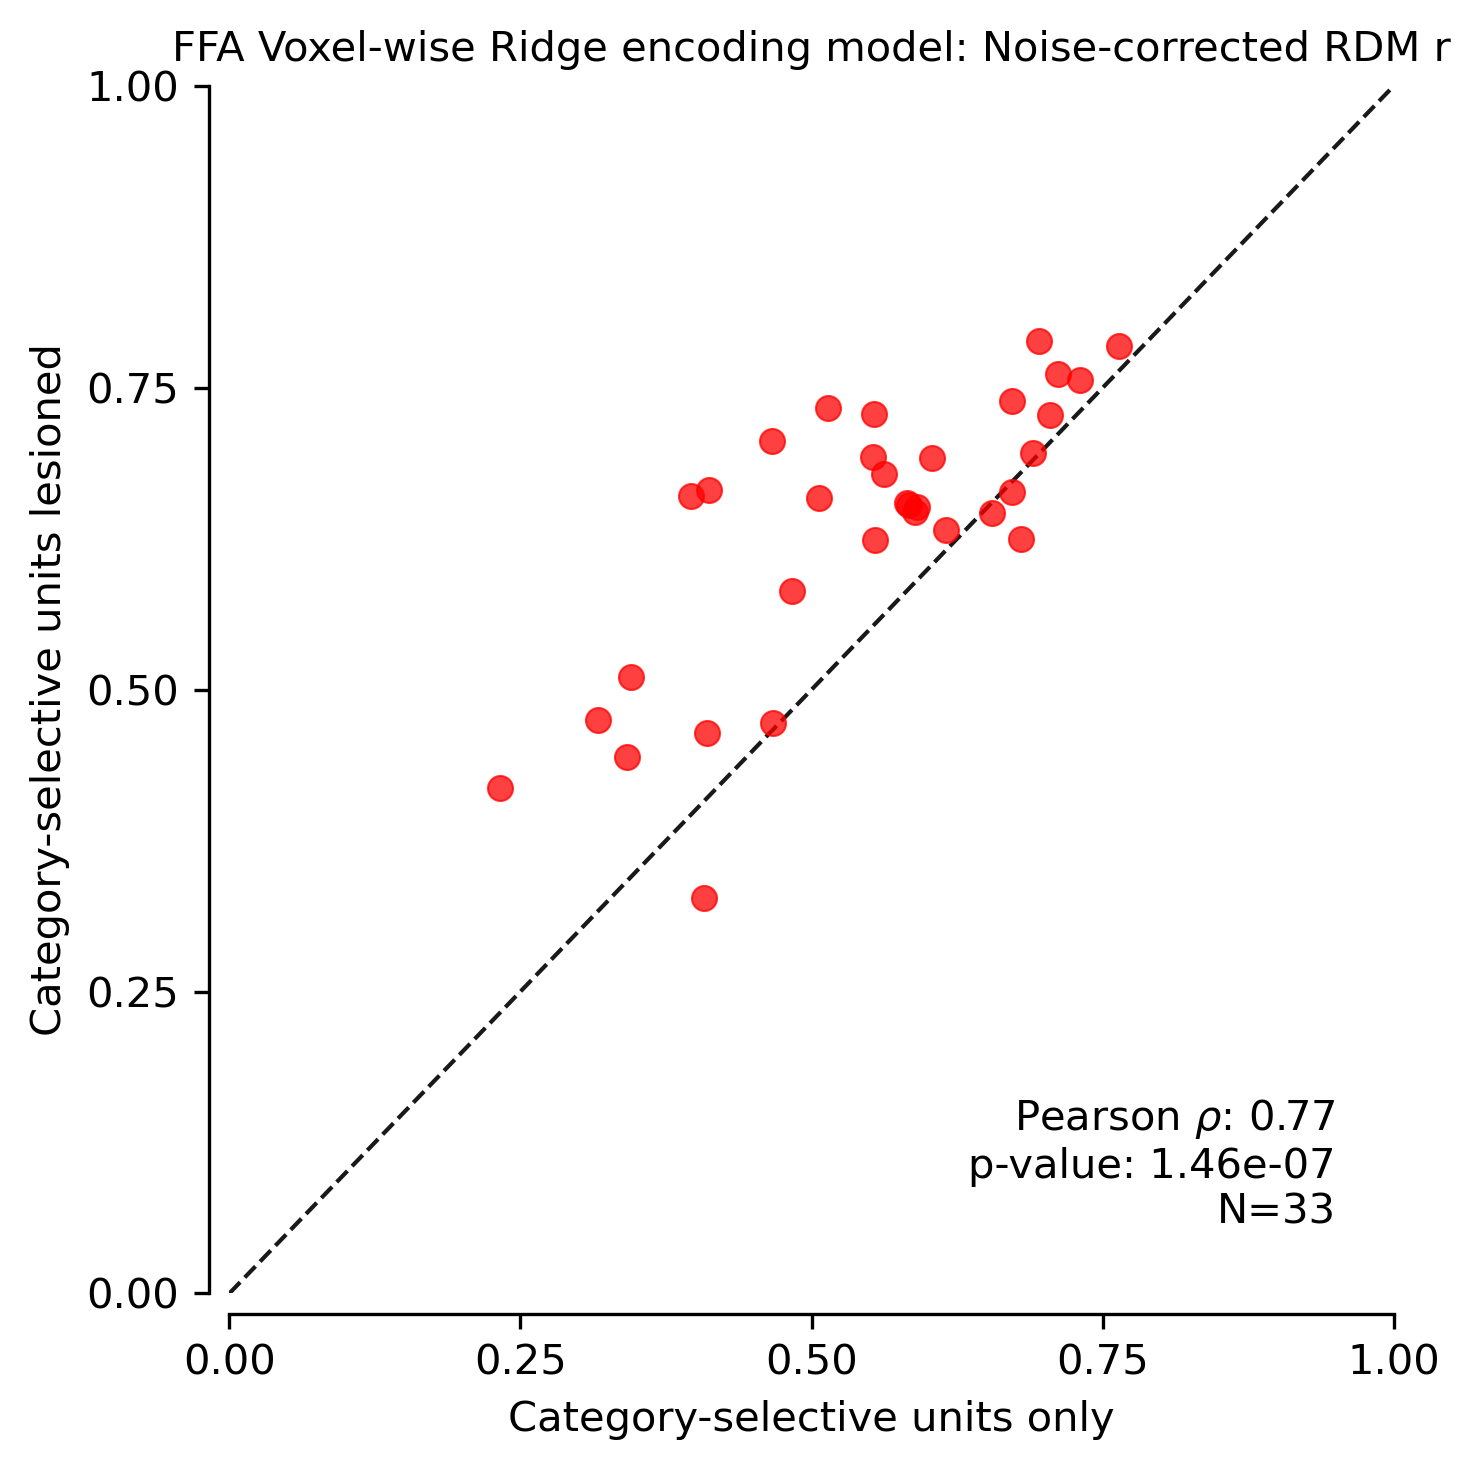

PPA


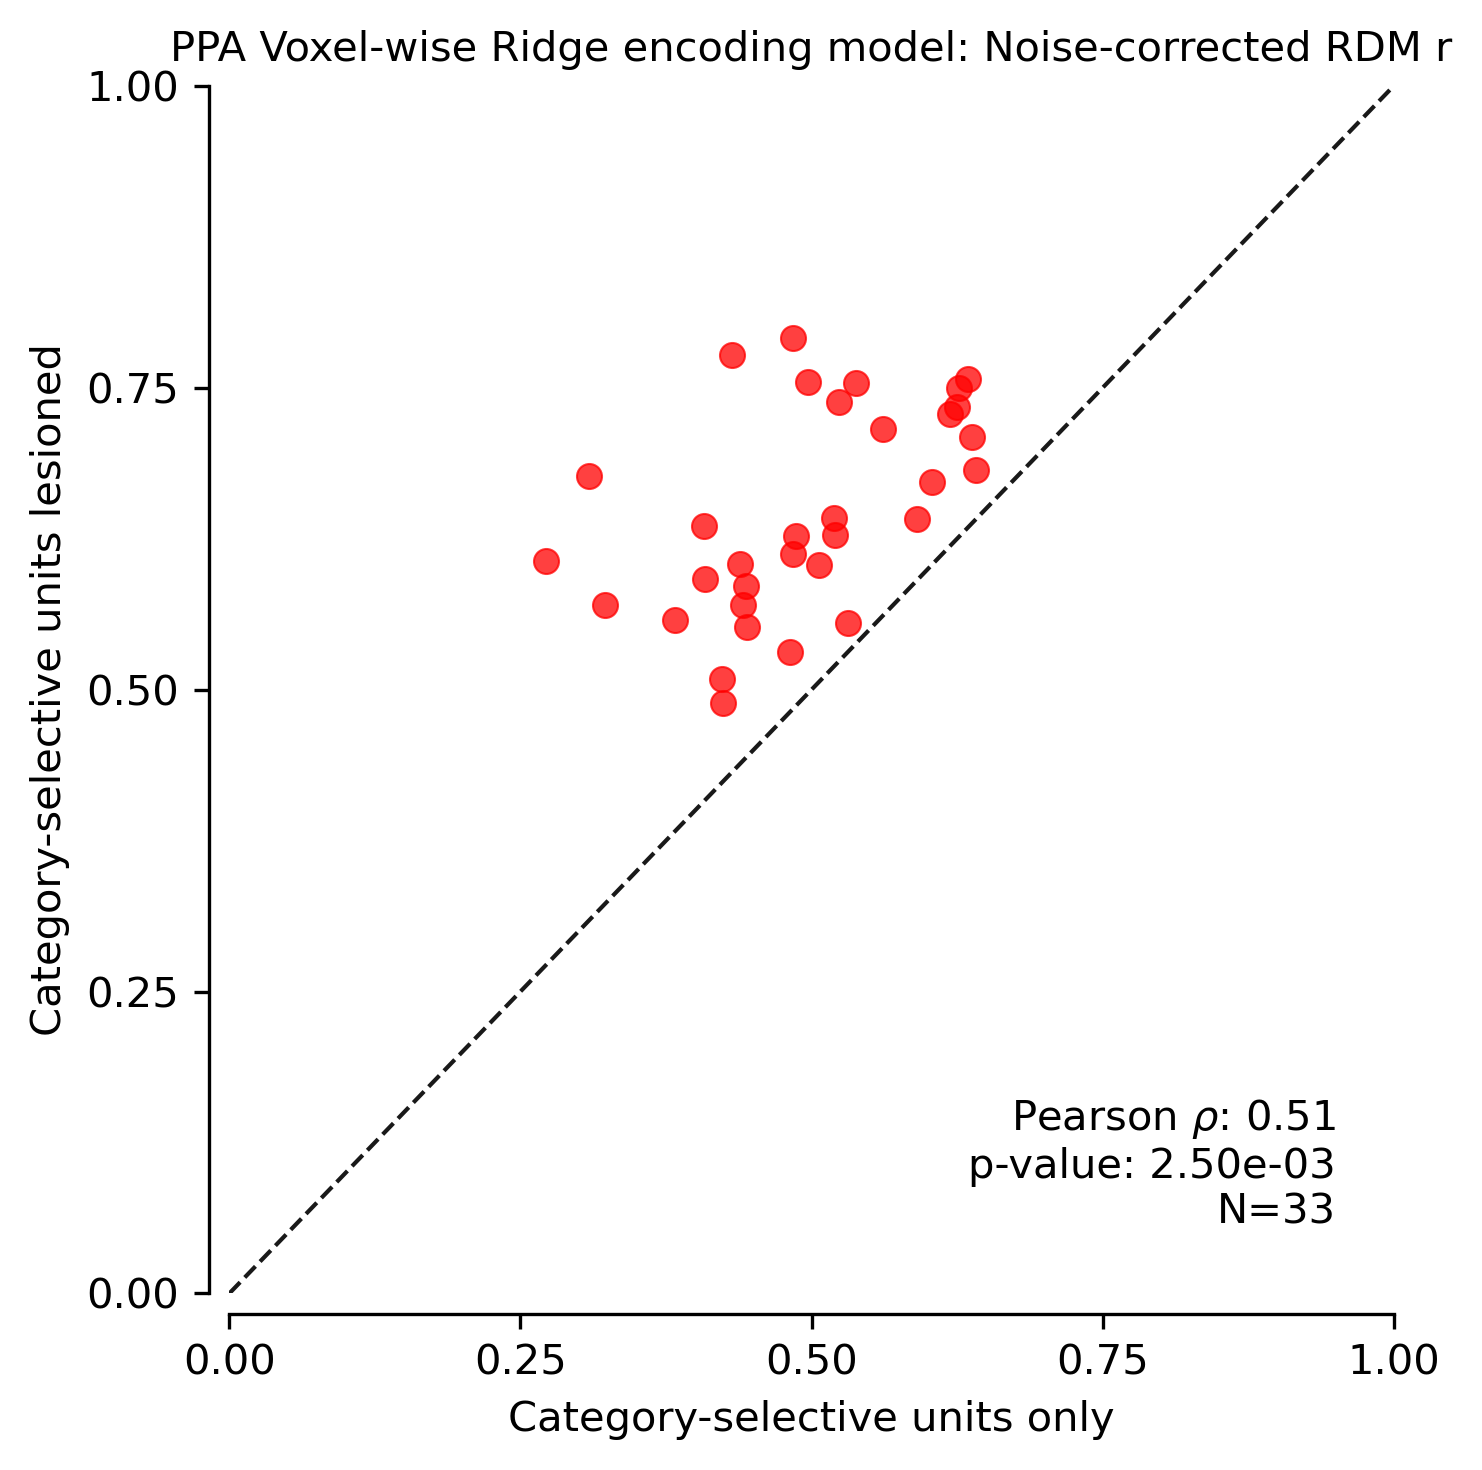

EBA


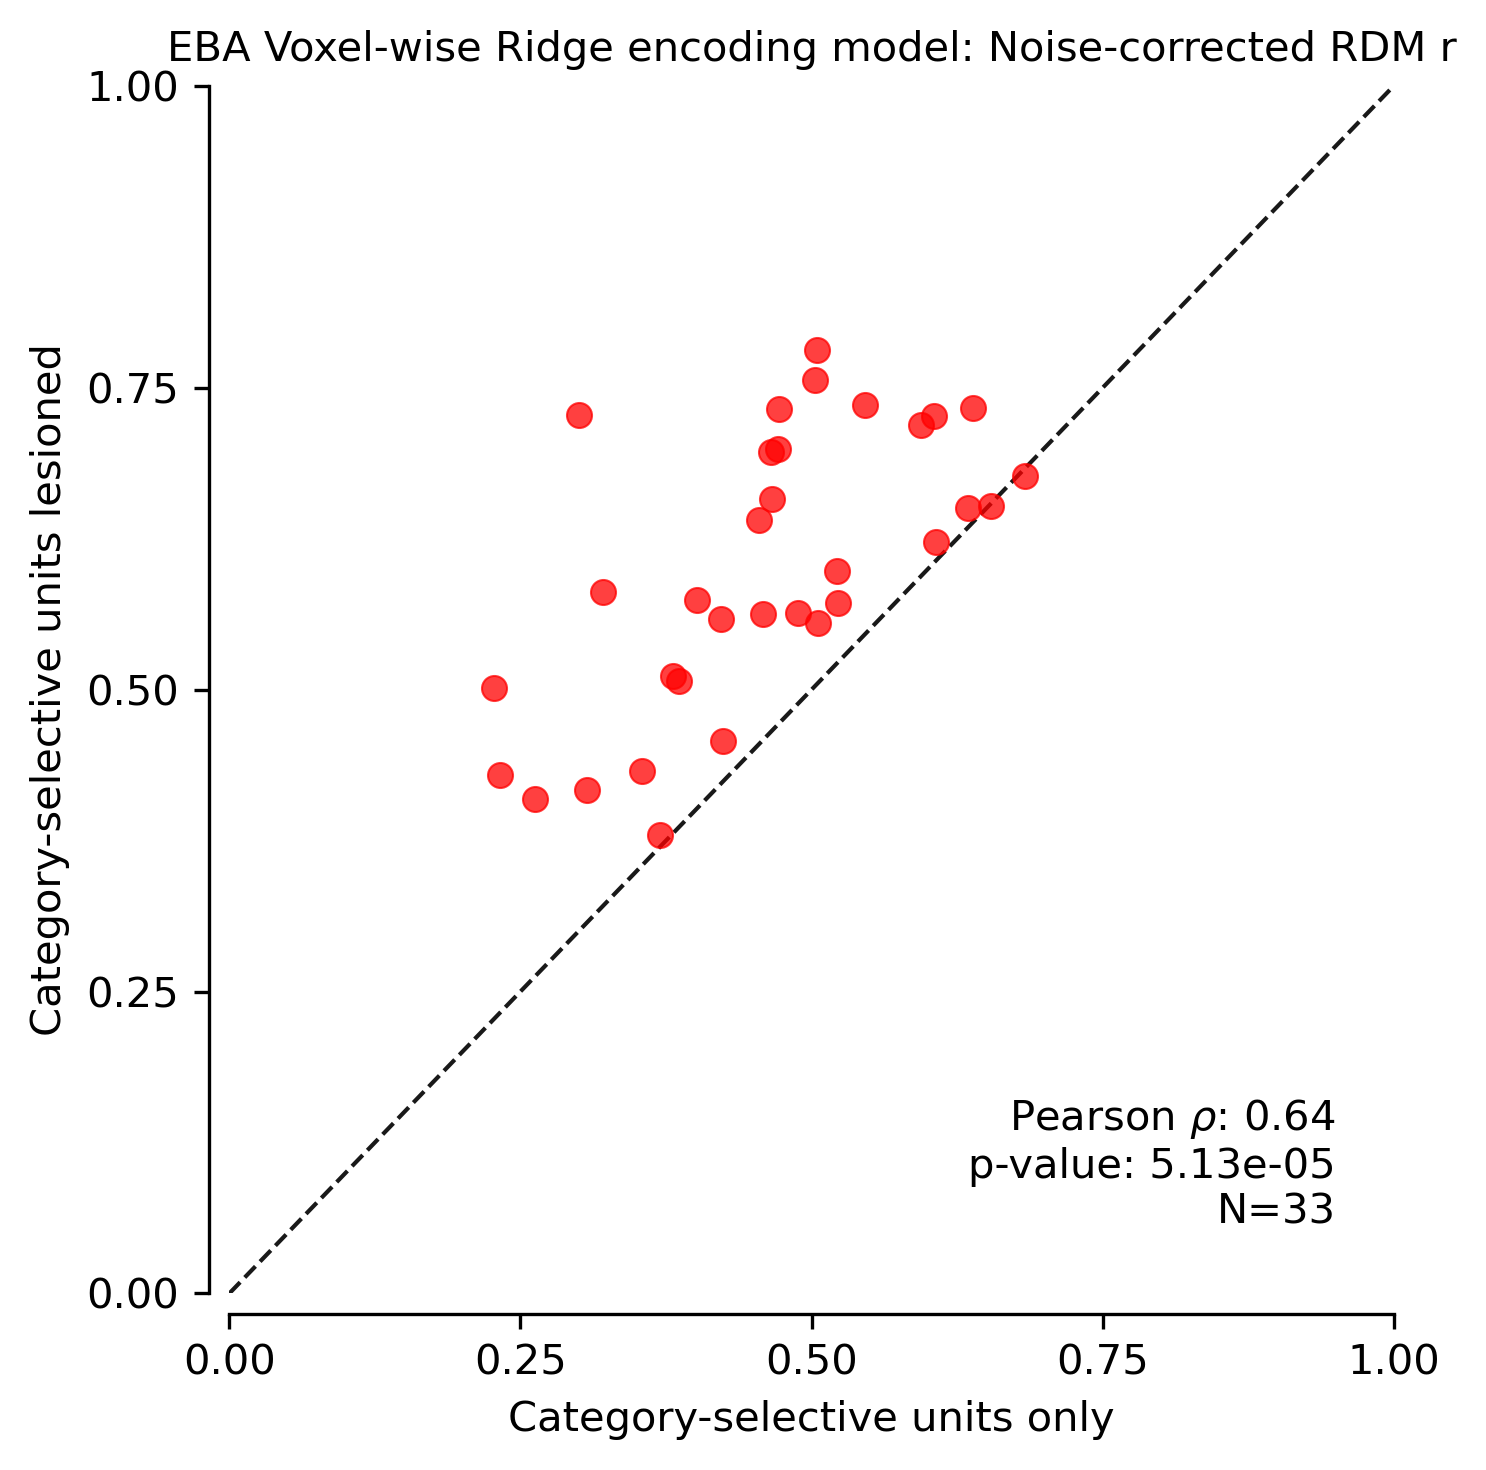

In [3]:
# Grill-Spector localization validation on X localizer
savefig = False

plot_dir = f'{PLOTS_DIR}/v2/lesions'
os.makedirs(plot_dir, exist_ok=True)

results_df = ridge_lesion_csv.copy()
frois = results_df['model_froi'].unique()

for froi in frois:
    print(froi)
    results_df = results_df.copy()
    model_names = results_df['model'].unique()
    n_models = len(model_names)
    xpts, ypts = [], []
    for i in range(len(model_names)):
        model_results = results_df[
                (results_df['model'] == model_names[i]) &
                (results_df['model_froi'] == froi) &
                (results_df['fmri_froi'] == froi)
            ]
        xpts.append(model_results['froi_normed_rdmr'].mean())
        ypts.append(model_results['lesion_normed_rdmr'].mean())

    fig = plt.figure(figsize=(5, 5), dpi=300)
    xpadpercent = 0.1
    plt.xticks([0, 0.25, 0.5, 0.75, 1])
    plt.xlim(0, 1)
    plt.gca().spines['bottom'].set_bounds(0, 1)
    xmin, xmax = plt.xlim()
    x_range = np.linspace(xmin, xmax, 100)
    plt.plot(x_range, x_range, 'k--', alpha=0.9, linewidth=1, clip_on=True)
    # plt.plot(localization_tvalues, m*localization_tvalues + b, 'k--', alpha=0.9)
    plt.scatter(xpts, ypts, color='red', alpha=0.75, zorder=2, linewidths=0.5)

    # Calculate Pearson correlation
    r, p_value = scipy.stats.pearsonr(xpts, ypts)
    plt.text(0.95, 0.05,
             rf"Pearson $\rho$: {r:.2f}" + '\n' + f"p-value: {p_value:.2e}" +  '\n'+  f"N={n_models}",
             horizontalalignment='right', verticalalignment='bottom',
             transform=plt.gca().transAxes)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 0.25, 0.5, 0.75, 1])
    plt.ylim(0, 1)
    plt.gca().spines['left'].set_bounds(0, 1)

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])
    plt.ylabel('Category-selective units lesioned')
    plt.xlabel('Category-selective units only')
    plt.title(f'{froi} Voxel-wise Ridge encoding model: Noise-corrected RDM r', fontsize=10)
    plt.tight_layout()
    if savefig:
        plt.savefig(f'{plot_dir}/lesioned_ridge_rdmr_{froi}.png', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    plt.close()

FFA


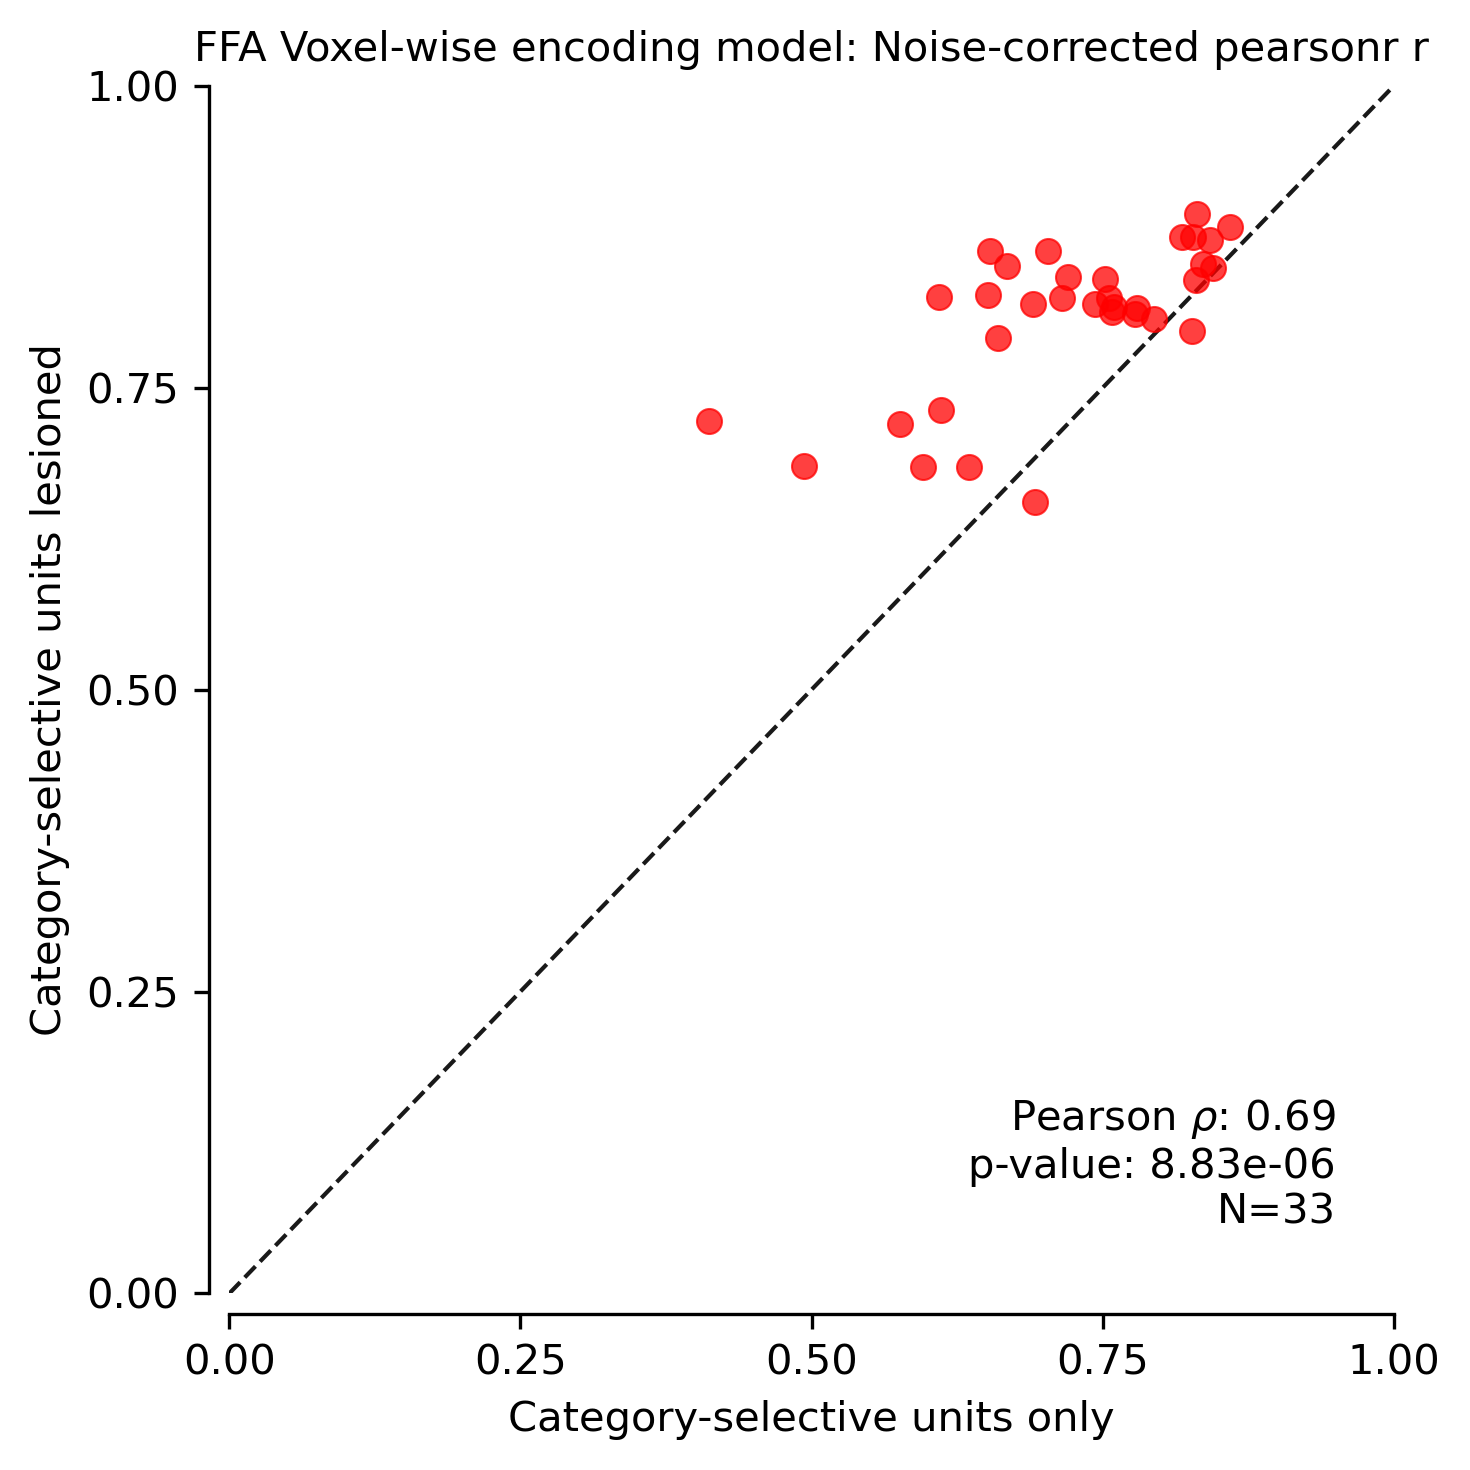

PPA


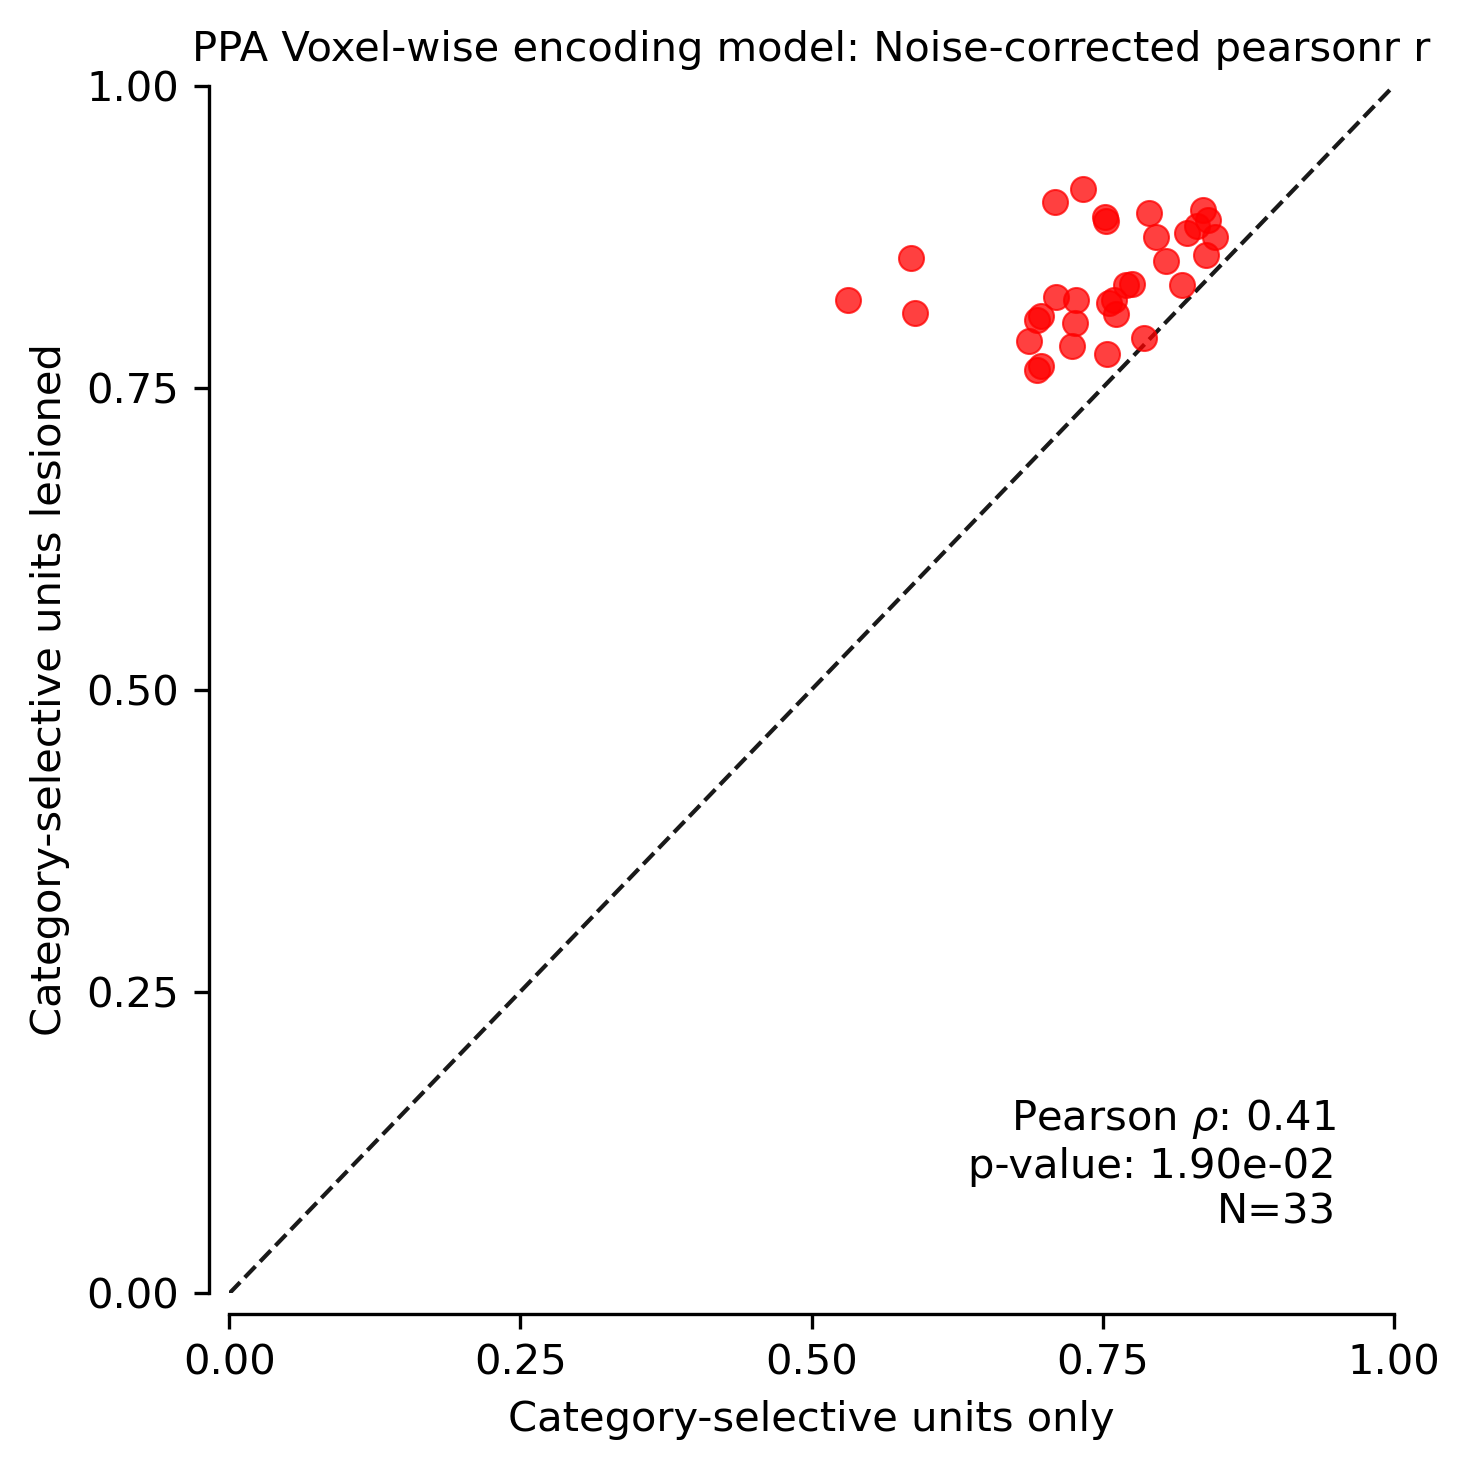

EBA


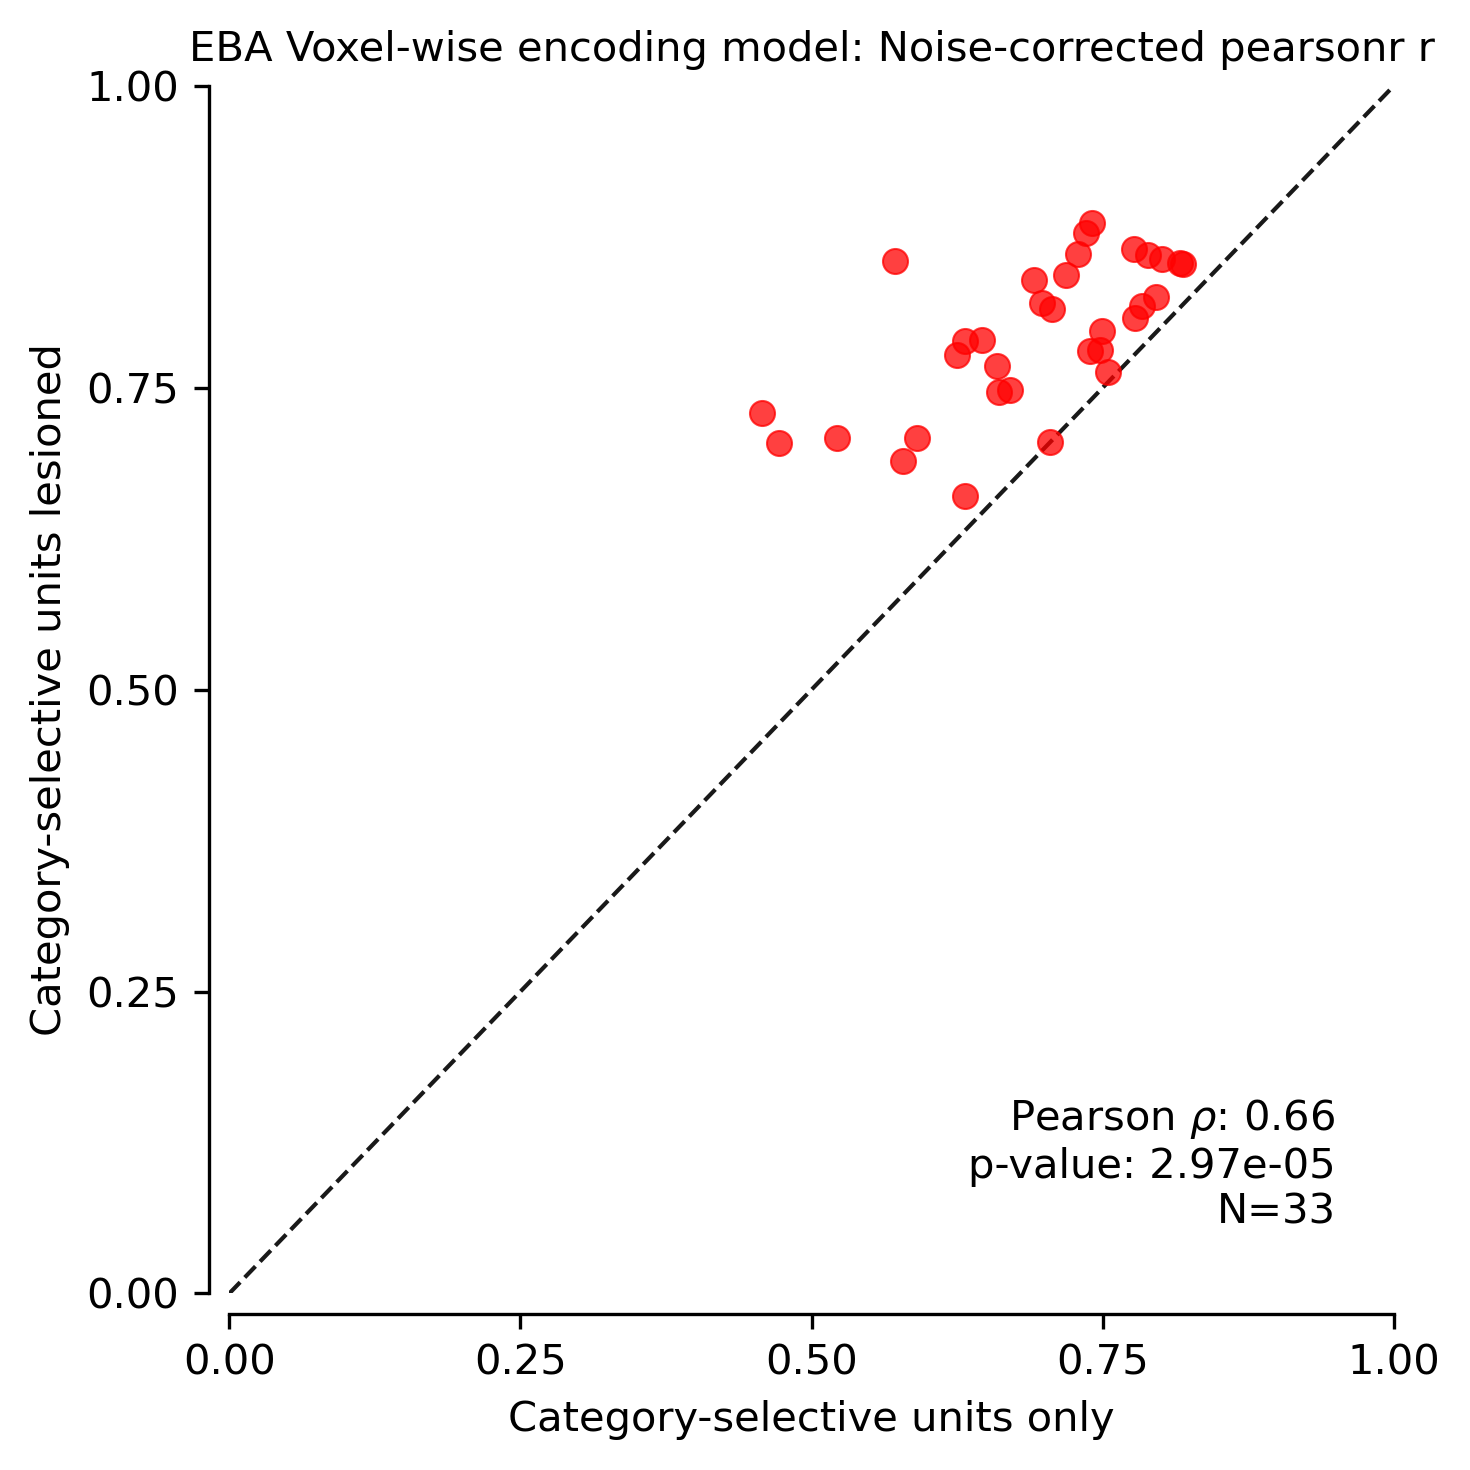

In [ ]:
# Grill-Spector localization validation on X localizer
savefig = False

plot_dir = f'{PLOTS_DIR}/v2/lesions'
os.makedirs(plot_dir, exist_ok=True)

results_df = ridge_lesion_csv.copy()
frois = results_df['model_froi'].unique()

for froi in frois:
    print(froi)
    model_names = results_df['model'].unique()
    n_models = len(model_names)
    xpts, ypts = [], []
    for i in range(len(model_names)):
        model_results = results_df[
                (results_df['model'] == model_names[i]) &
                (results_df['model_froi'] == froi) &
                (results_df['fmri_froi'] == froi)
            ]
        xpts.append(model_results['froi_normed_pearsonr'].mean())
        ypts.append(model_results['lesion_normed_pearsonr'].mean())

    fig = plt.figure(figsize=(5, 5), dpi=300)
    xpadpercent = 0.1
    plt.xticks([0, 0.25, 0.5, 0.75, 1])
    plt.xlim(0, 1)
    plt.gca().spines['bottom'].set_bounds(0, 1)
    xmin, xmax = plt.xlim()
    x_range = np.linspace(xmin, xmax, 100)
    plt.plot(x_range, x_range, 'k--', alpha=0.9, linewidth=1, clip_on=True)
    # plt.plot(localization_tvalues, m*localization_tvalues + b, 'k--', alpha=0.9)
    plt.scatter(xpts, ypts, color='red', alpha=0.75, zorder=2, linewidths=0.5)

    # Calculate Pearson correlation
    r, p_value = scipy.stats.pearsonr(xpts, ypts)
    plt.text(0.95, 0.05,
             rf"Pearson $\rho$: {r:.2f}" + '\n' + f"p-value: {p_value:.2e}" +  '\n'+  f"N={n_models}",
             horizontalalignment='right', verticalalignment='bottom',
             transform=plt.gca().transAxes)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 0.25, 0.5, 0.75, 1])
    plt.ylim(0, 1)
    plt.gca().spines['left'].set_bounds(0, 1)

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])
    plt.ylabel('Category-selective units lesioned')
    plt.xlabel('Category-selective units only')
    plt.title(f'{froi} Voxel-wise Ridge encoding model: Noise-corrected pearsonr r', fontsize=10)
    plt.tight_layout()
    if savefig:
        plt.savefig(f'{plot_dir}/lesioned_ridge_pearsonr_{froi}.png', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    plt.close()

## L1-positive

In [5]:
l1pos_lesion_csv_path = f'{RESULTS_DIR}/nsd515_l1pos_lesion.csv'
l1pos_lesion_csvs = [f'{RESULTS_DIR}/nsd515_lesion_ems_l1pos_v{i}.csv' for i in [1, 2, 3, 4, 5, 7]]

if not os.path.exists(l1pos_lesion_csv_path):
    l1pos_lesion_csv = pd.concat([pd.read_csv(l1pos_lesion_csv) for l1pos_lesion_csv in l1pos_lesion_csvs])
    l1pos_lesion_csv.to_csv(l1pos_lesion_csv_path, index=False)
else:
    l1pos_lesion_csv = pd.read_csv(l1pos_lesion_csv_path)

FFA


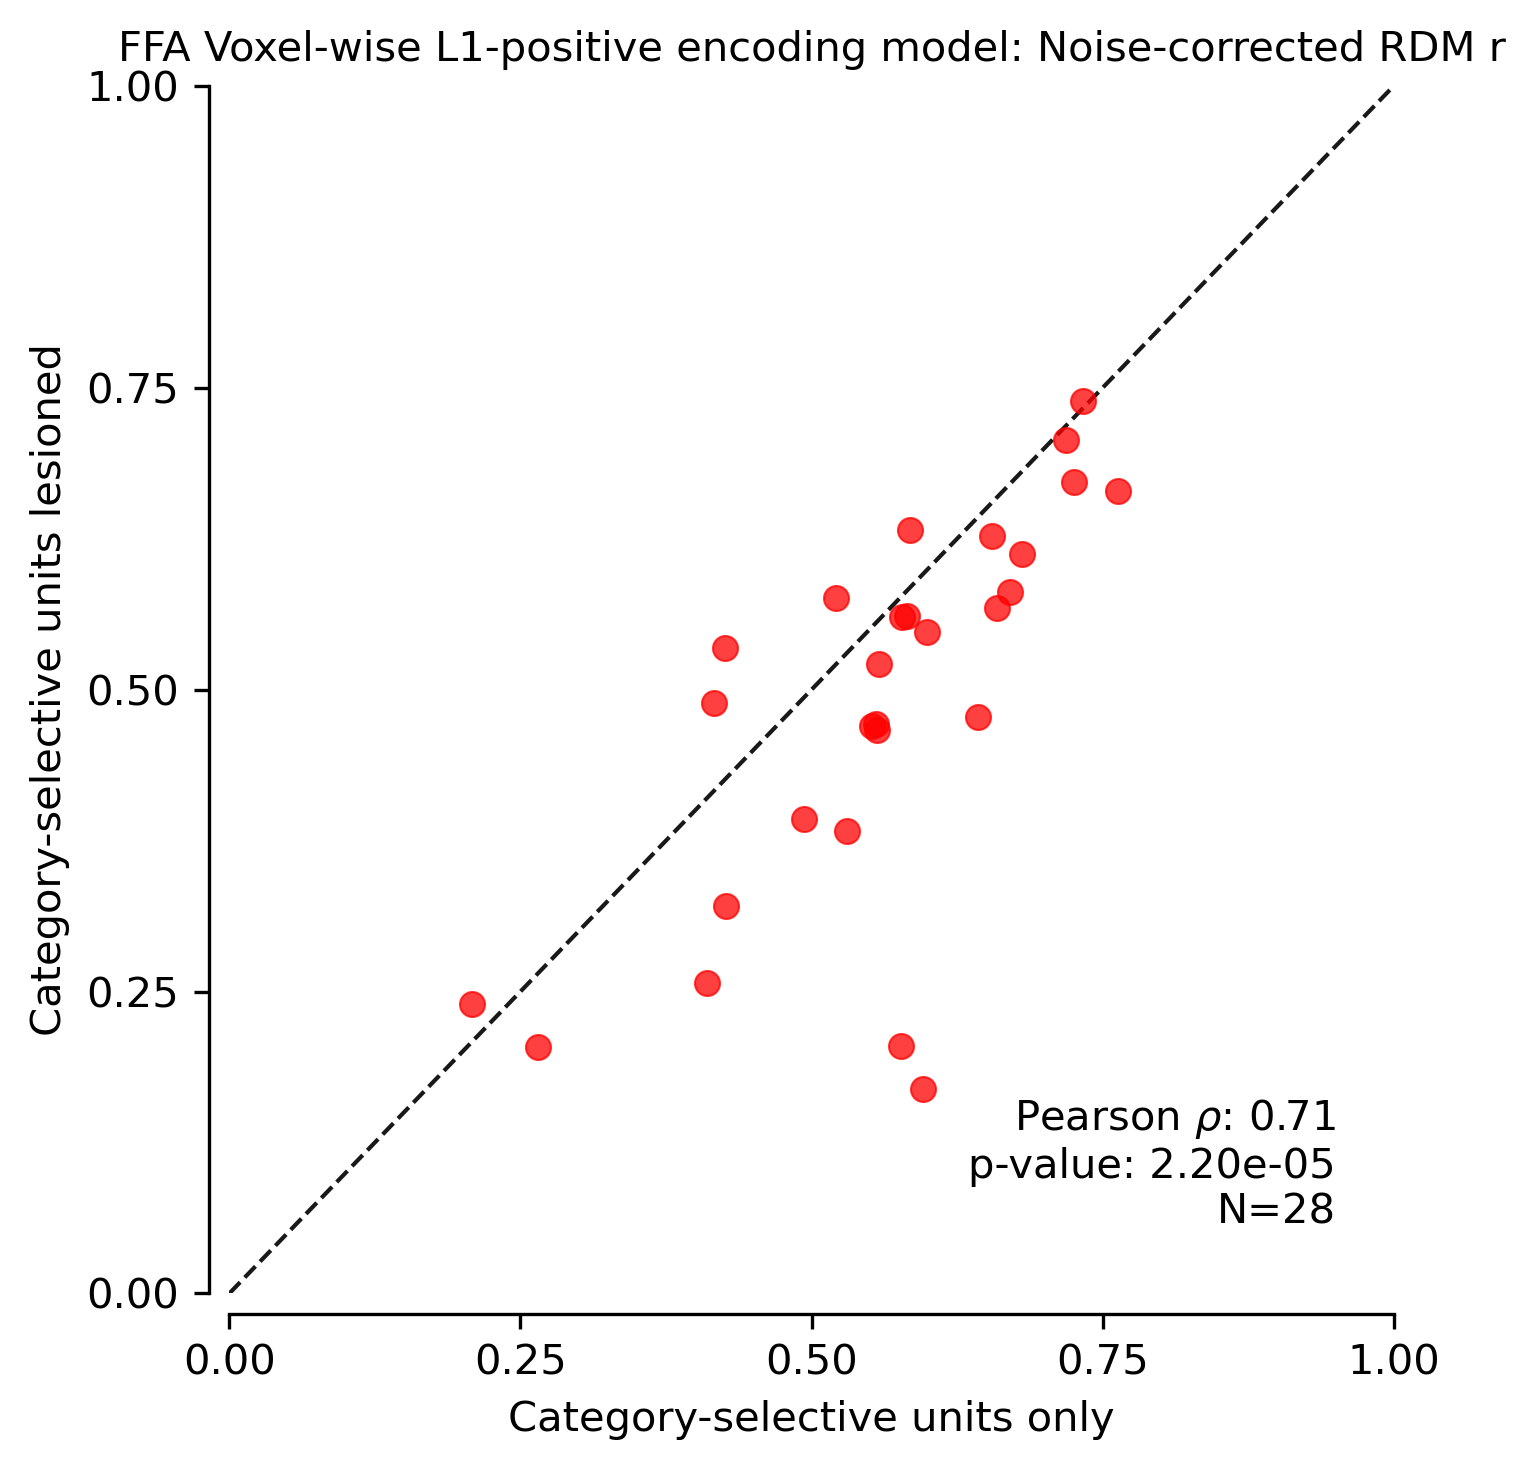

PPA


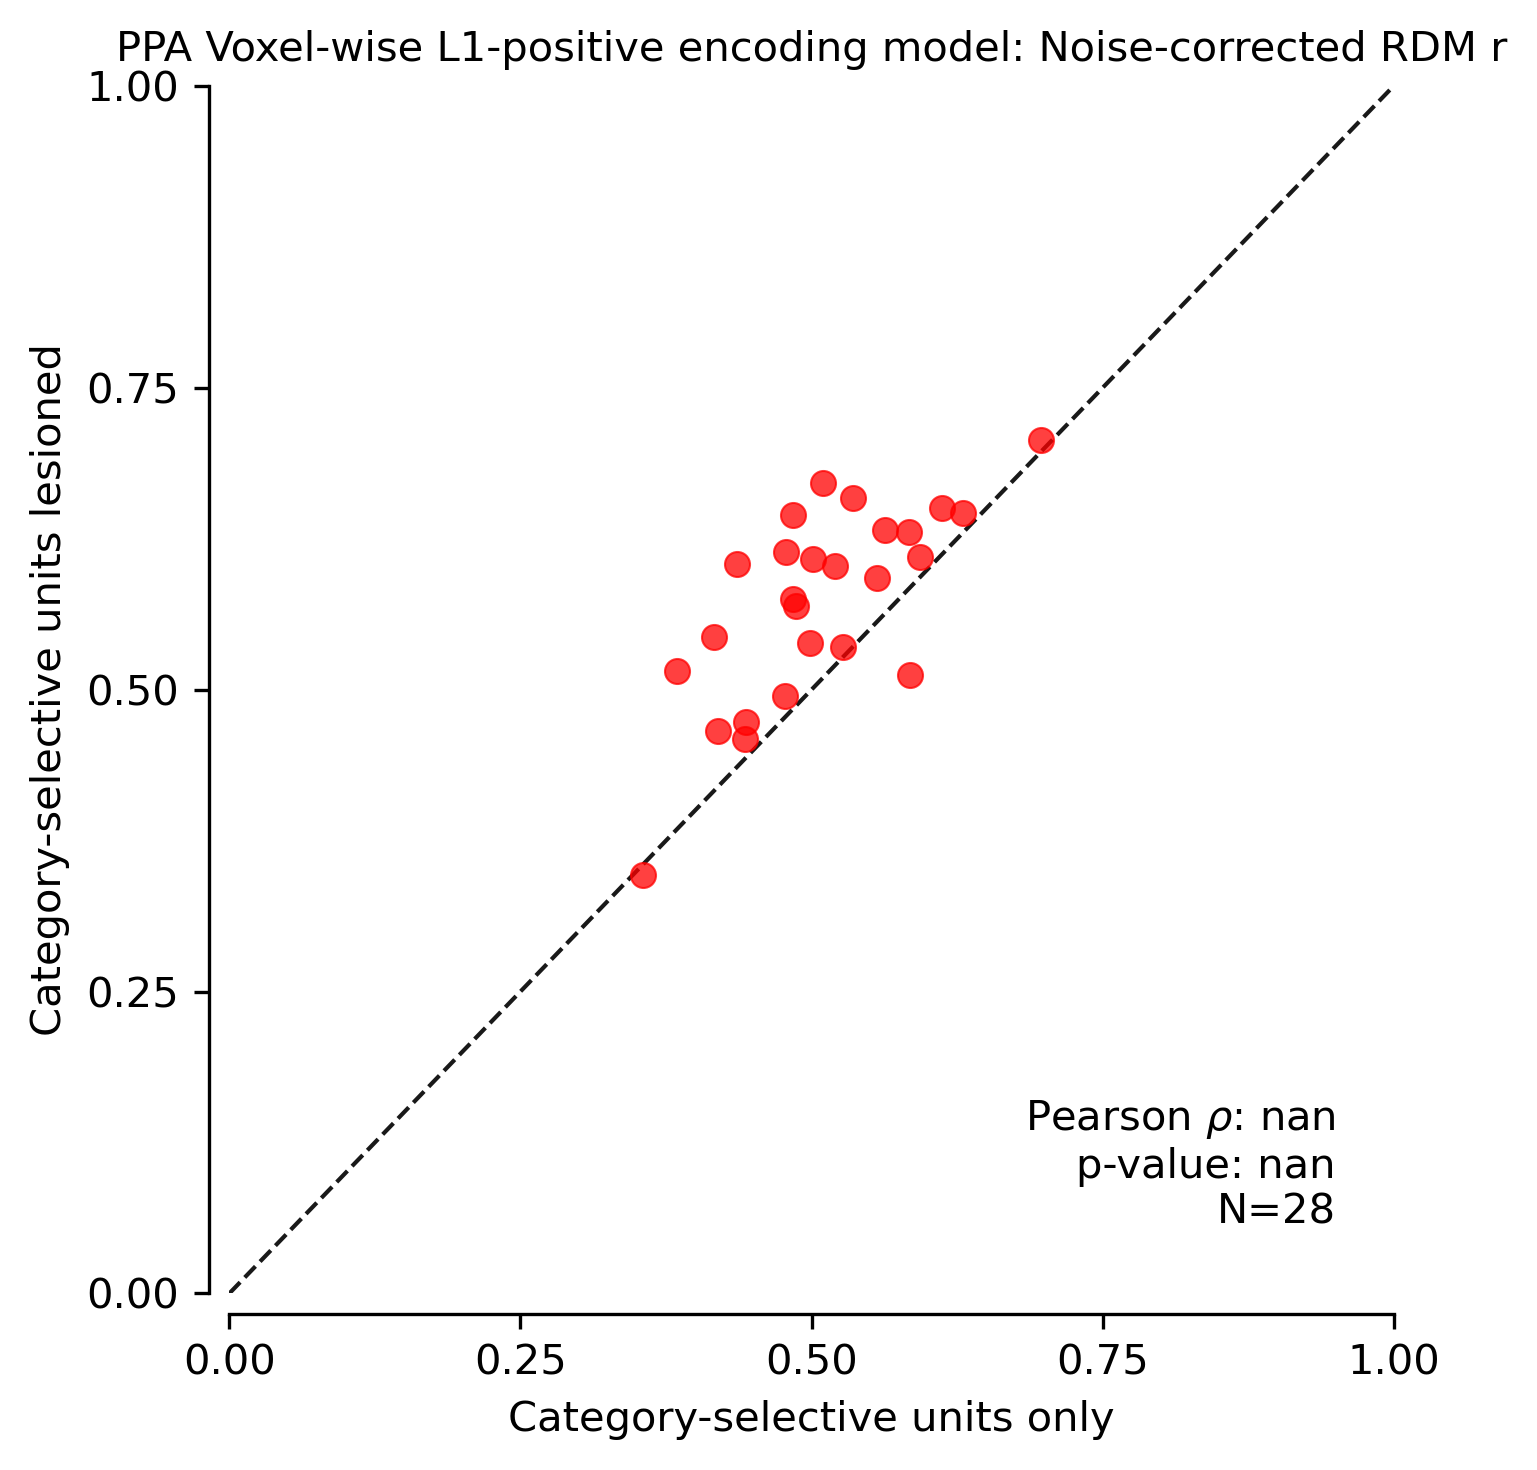

EBA


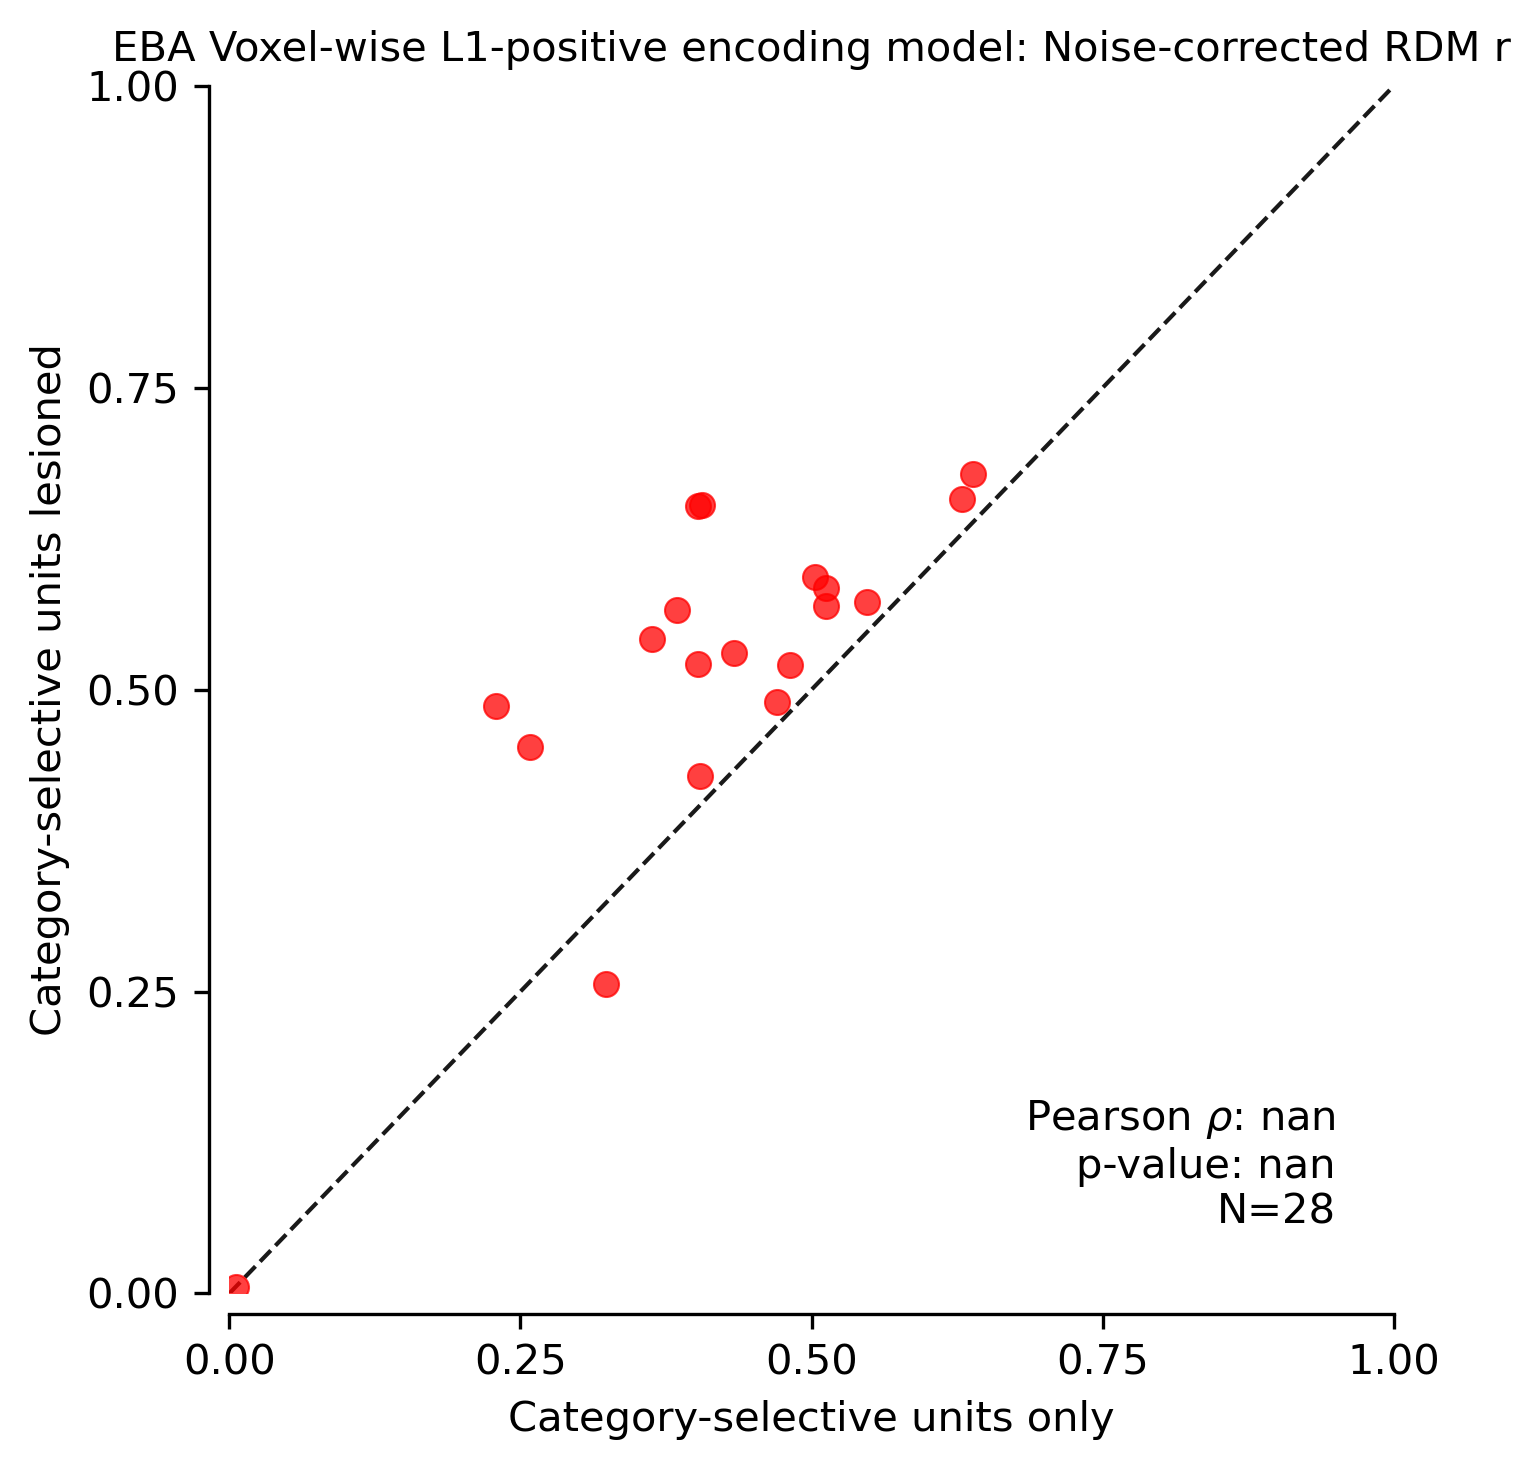

In [6]:
# Grill-Spector localization validation on X localizer
savefig = False

plot_dir = f'{PLOTS_DIR}/v2/lesions'
os.makedirs(plot_dir, exist_ok=True)

results_df = l1pos_lesion_csv.copy()
frois = results_df['model_froi'].unique()

for froi in frois:
    print(froi)
    model_names = results_df['model'].unique()
    n_models = len(model_names)
    xpts, ypts = [], []
    for i in range(len(model_names)):
        model_results = results_df[
                (results_df['model'] == model_names[i]) &
                (results_df['model_froi'] == froi) &
                (results_df['fmri_froi'] == froi)
            ]
        xpts.append(model_results['froi_normed_rdmr'].mean())
        ypts.append(model_results['lesion_normed_rdmr'].mean())

    fig = plt.figure(figsize=(5, 5), dpi=300)
    xpadpercent = 0.1
    plt.xticks([0, 0.25, 0.5, 0.75, 1])
    plt.xlim(0, 1)
    plt.gca().spines['bottom'].set_bounds(0, 1)
    xmin, xmax = plt.xlim()
    x_range = np.linspace(xmin, xmax, 100)
    plt.plot(x_range, x_range, 'k--', alpha=0.9, linewidth=1, clip_on=True)
    # plt.plot(localization_tvalues, m*localization_tvalues + b, 'k--', alpha=0.9)
    plt.scatter(xpts, ypts, color='red', alpha=0.75, zorder=2, linewidths=0.5)

    # Calculate Pearson correlation
    r, p_value = scipy.stats.pearsonr(xpts, ypts)
    plt.text(0.95, 0.05,
             rf"Pearson $\rho$: {r:.2f}" + '\n' + f"p-value: {p_value:.2e}" +  '\n'+  f"N={n_models}",
             horizontalalignment='right', verticalalignment='bottom',
             transform=plt.gca().transAxes)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 0.25, 0.5, 0.75, 1])
    plt.ylim(0, 1)
    plt.gca().spines['left'].set_bounds(0, 1)

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])
    plt.ylabel('Category-selective units lesioned')
    plt.xlabel('Category-selective units only')
    plt.title(f'{froi} Voxel-wise L1-positive encoding model: Noise-corrected RDM r', fontsize=10)
    plt.tight_layout()
    if savefig:
        plt.savefig(f'{plot_dir}/lesioned_l1pos_rdmr_{froi}.png', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    plt.close()

FFA


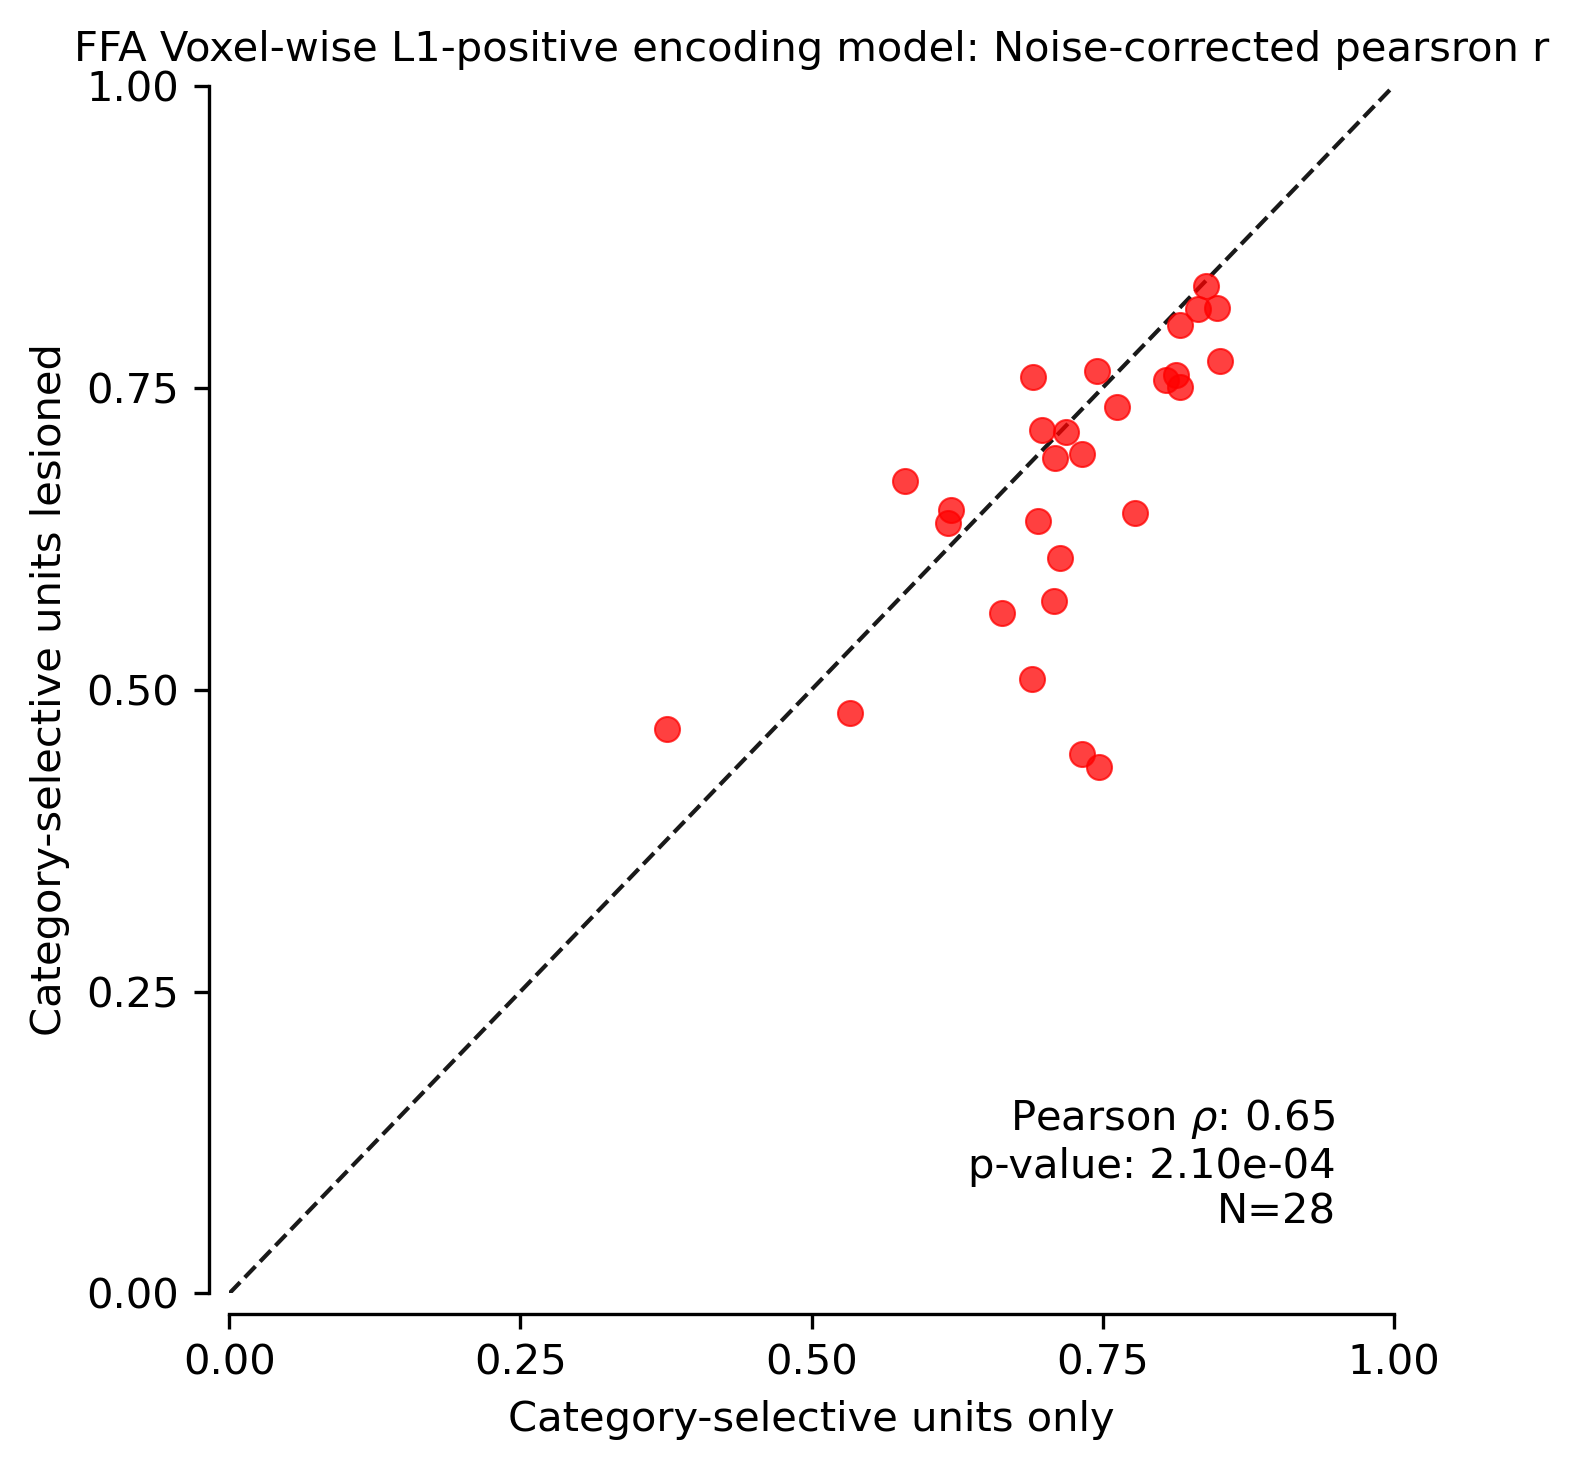

PPA


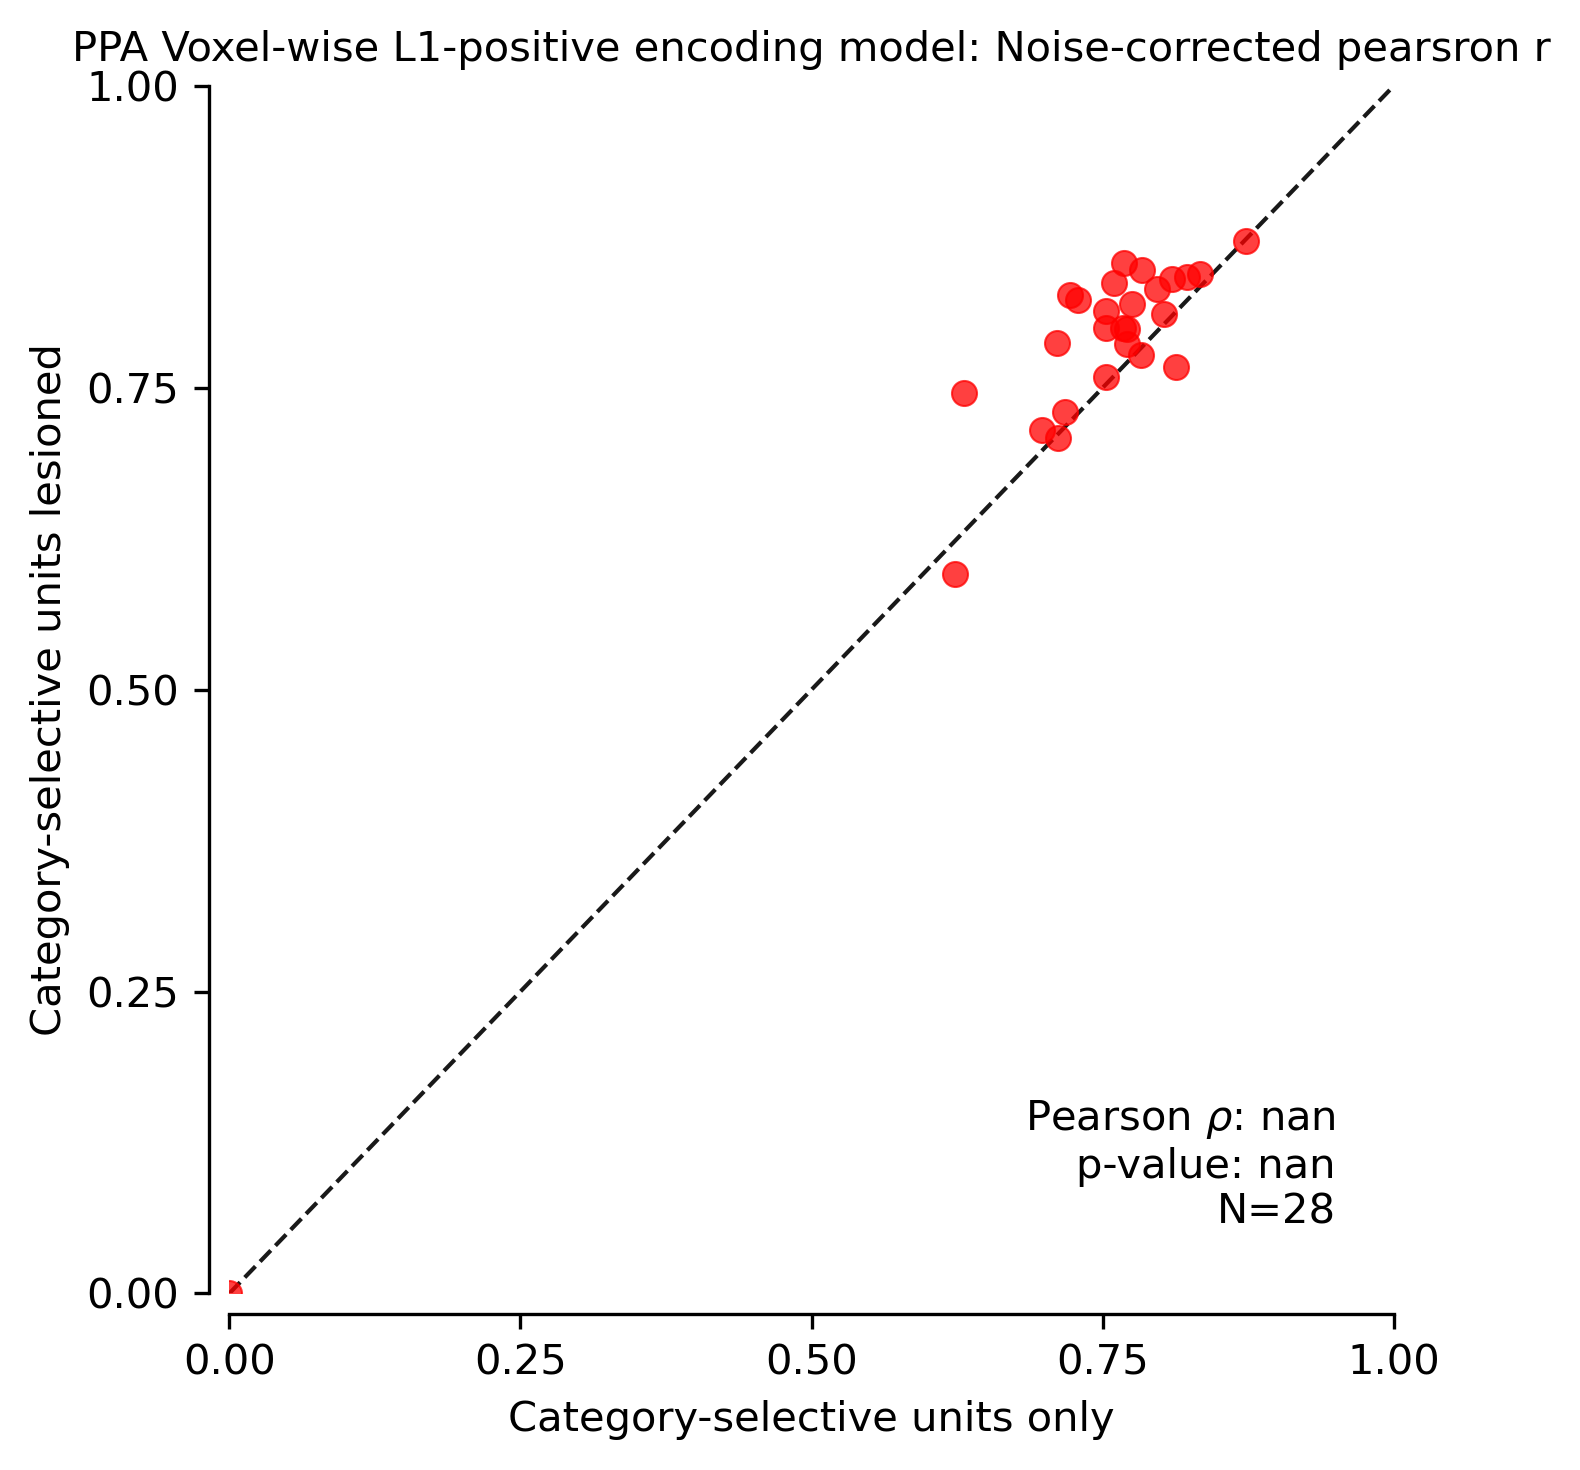

EBA


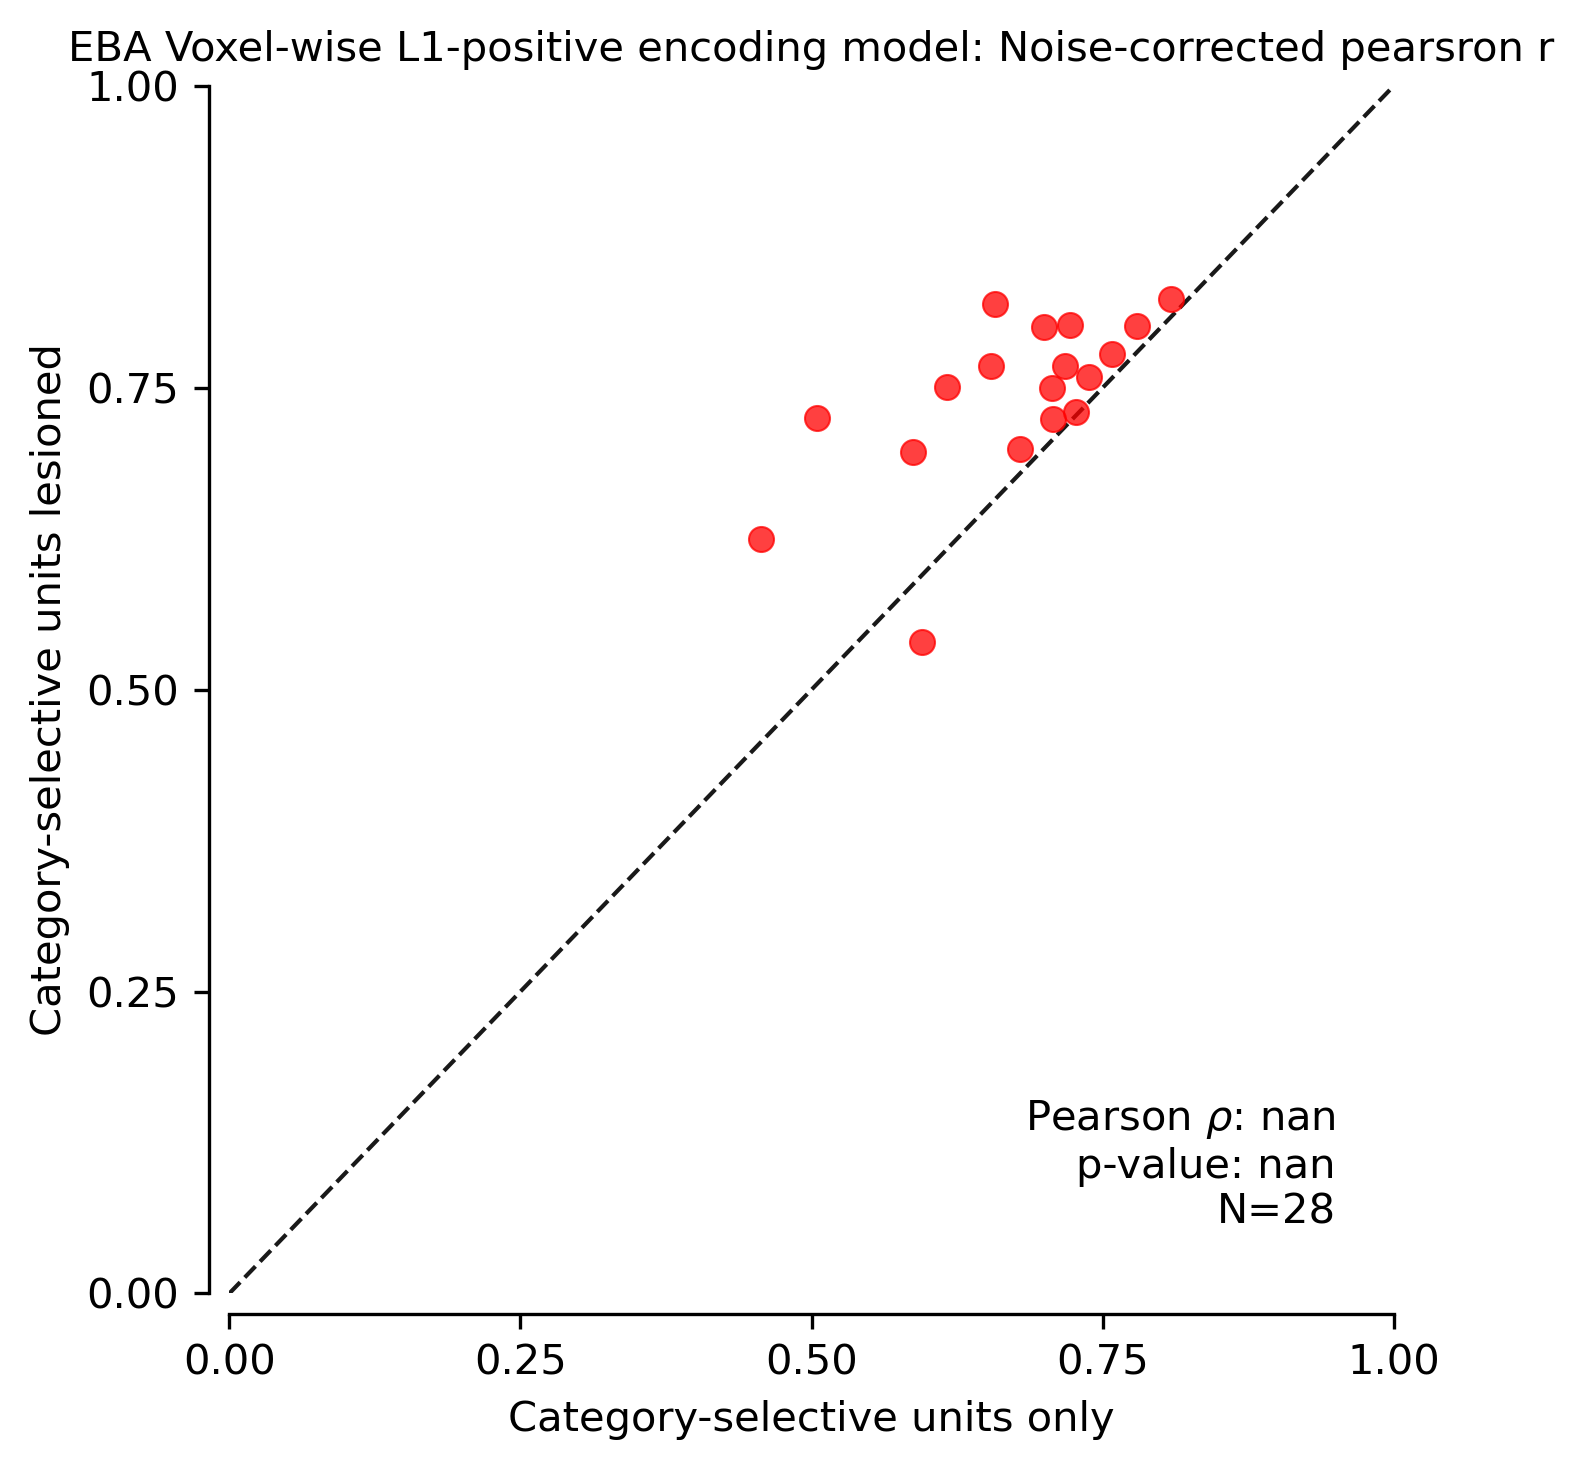

In [7]:
# Grill-Spector localization validation on X localizer
savefig = False

plot_dir = f'{PLOTS_DIR}/v2/lesions'
os.makedirs(plot_dir, exist_ok=True)

results_df = l1pos_lesion_csv.copy()
frois = results_df['model_froi'].unique()

for froi in frois:
    print(froi)
    model_names = results_df['model'].unique()
    n_models = len(model_names)
    xpts, ypts = [], []
    for i in range(len(model_names)):
        model_results = results_df[
                (results_df['model'] == model_names[i]) &
                (results_df['model_froi'] == froi) &
                (results_df['fmri_froi'] == froi)
            ]
        xpts.append(model_results['froi_normed_pearsonr'].mean())
        ypts.append(model_results['lesion_normed_pearsonr'].mean())

    fig = plt.figure(figsize=(5, 5), dpi=300)
    xpadpercent = 0.1
    plt.xticks([0, 0.25, 0.5, 0.75, 1])
    plt.xlim(0, 1)
    plt.gca().spines['bottom'].set_bounds(0, 1)
    xmin, xmax = plt.xlim()
    x_range = np.linspace(xmin, xmax, 100)
    plt.plot(x_range, x_range, 'k--', alpha=0.9, linewidth=1, clip_on=True)
    # plt.plot(localization_tvalues, m*localization_tvalues + b, 'k--', alpha=0.9)
    plt.scatter(xpts, ypts, color='red', alpha=0.75, zorder=2, linewidths=0.5)

    # Calculate Pearson correlation
    r, p_value = scipy.stats.pearsonr(xpts, ypts)
    plt.text(0.95, 0.05,
             rf"Pearson $\rho$: {r:.2f}" + '\n' + f"p-value: {p_value:.2e}" +  '\n'+  f"N={n_models}",
             horizontalalignment='right', verticalalignment='bottom',
             transform=plt.gca().transAxes)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.yticks([0, 0.25, 0.5, 0.75, 1])
    plt.ylim(0, 1)
    plt.gca().spines['left'].set_bounds(0, 1)

    # if froi != 'FFA':
    #     plt.gca().spines['left'].set_visible(False)
    #     # Stop showing y-axis ticks
    #     plt.gca().yaxis.set_ticks([])
    plt.ylabel('Category-selective units lesioned')
    plt.xlabel('Category-selective units only')
    plt.title(f'{froi} Voxel-wise L1-positive encoding model: Noise-corrected pearsron r', fontsize=10)
    plt.tight_layout()
    if savefig:
        plt.savefig(f'{plot_dir}/lesioned_l1pos_pearsonr_{froi}.png', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    plt.close()

# Bonus

In [ ]:
import os
from PIL import Image

import matplotlib.pyplot as plt

# Create output directory if it doesn't exist
output_dir = 'results/plots/vss25_presentation/bonus'
os.makedirs(output_dir, exist_ok=True)

# Selected NSD IDs
selected_nsdids = [2429, 38634, 1814, 64483, 47598, 49]

# Loop through each selected NSD ID
for nsdid in selected_nsdids:
    # Get the image from allstim
    img = allstim[nsdid]
    
    # Create a figure with no margins
    fig = plt.figure(figsize=(5, 5), dpi=300)
    ax = plt.Axes(fig, [0., 0., 1., 1.])
    ax.set_axis_off()
    fig.add_axes(ax)
    
    # Display and save the image
    ax.imshow(img)
    
    # Save as high-quality JPEG
    filename = os.path.join(output_dir, f'nsdid_{nsdid}.jpg')
    plt.savefig(filename, bbox_inches='tight', pad_inches=0, dpi=300, format='jpg')
    plt.close(fig)
    
    print(f"Saved {filename}")
    
    # Additionally save using PIL for potentially better quality
    # pil_img = Image.fromarray(img)
    # pil_filename = os.path.join(output_dir, f'nsdid_{nsdid}_pil.jpg')
    # pil_img.save(pil_filename, format='JPEG', quality=95)
    # print(f"Saved {pil_filename}")

print(f"All images saved to {output_dir}")
